# Cancer Inhibitors — Classical ML, QML, and Explainable AI

**Dataset:** [Kaggle — Cancer Inhibitors by Kelvin Xiao](https://www.kaggle.com/datasets/xiaotawkaggle/inhibitors)  
**Task:** Predict whether a small molecule inhibits one selected protein kinase using molecular fingerprint features.

## What this notebook does

1. Loads the original **HDF5** release (`ap`, `mg`, and `tt` fingerprints; 6,117 features in the documented version).
2. Audits data quality and creates a comprehensive EDA plot suite: class balance, missingness, fingerprint activity, sparsity, distributions, low-dimensional projection, feature prevalence, and selected-feature correlations.
3. Uses a stratified train/validation/test split with an untouched test set.
4. Trains transparent classical baselines (regularised logistic regression and Extra Trees).
5. Trains **two self-supervised pre-trained fingerprint models** (frozen linear probe and fine-tuned head) plus a **pure 1-D CNN trained from scratch**.
6. Benchmarks a variational **Quantum Machine Learning (QML)** classifier on a compact, train-only fingerprint representation.
7. Provides an optional, *genuinely pre-trained molecular language model* (**ChemBERTa**) path. It first resolves ChEMBL IDs to SMILES, because the Kaggle file does not include SMILES strings.
8. Applies XAI using SHAP (tree model), Integrated Gradients (CNN), plus permutation and gradient explanations for the QML model; it can optionally score the supplied PubChem file.

> **Important scientific caveats**
> - The labels describe kinase-inhibition assay outcomes, **not a clinical cancer diagnosis or treatment recommendation**. Results are for research/model-development only and require prospective experimental validation.
> - Molecular fingerprint bit positions do not have an image-like spatial geometry. A 1-D CNN is included because requested, but tree/linear models and chemical foundation models are generally more chemically defensible inputs for this representation.
> - The dataset has no SMILES in its CSV release and only identifiers in HDF5. Therefore, direct bit-level explanations cannot automatically be converted to atom/substructure explanations without recovering molecular structures and the original fingerprint settings.

## Dataset structure and modelling choice

The source provides binary labels for eight kinase targets:
`cdk2`, `egfr_erbB1`, `gsk3b`, `hgfr`, `map_k_p38a`, `tpk_lck`, `tpk_src`, and `vegfr2`.

The HDF5 version holds a ChEMBL ID, a label, and three sparse feature blocks:

| Block | Meaning | Documented width |
|---|---|---:|
| `ap` | RDKit atom-pair fingerprints | 2,039 |
| `mg` | RDKit Morgan/circular fingerprints | 2,039 |
| `tt` | RDKit topological-torsion fingerprints | 2,039 |

This notebook trains one **binary model per run**. Set `TARGET` below and rerun for each kinase. This prevents incorrectly treating absent labels for other targets as negatives. The EDA and modelling code automatically accepts a different documented fingerprint width where available.

In [3]:
# Core configuration — change only this cell for a new target/run.
from pathlib import Path

TARGET = "cdk2"  # choose one of the targets below
TARGETS = ["cdk2", "egfr_erbB1", "gsk3b", "hgfr", "map_k_p38a", "tpk_lck", "tpk_src", "vegfr2"]
assert TARGET in TARGETS

# Point this to an extracted Kaggle dataset folder. On Kaggle, the locator below also searches /kaggle/input.
DATA_DIR = Path("./data/inhibitors")
DOWNLOAD_IF_MISSING = False  # True only after Kaggle API credentials are configured locally.

# Reproducibility and resource controls.
SEED = 42
FAST_RUN = False                 # True: fewer epochs / trees for a smoke test.
RUN_CHEMBERTA = False            # Requires Internet + ChEMBL access + GPU recommended.
RUN_QML = True                    # Variational quantum classifier; runs on a local state-vector simulator.
SCREEN_PUBCHEM = False           # Optional ranking only; not a clinical screening claim.

AE_EPOCHS = 8 if FAST_RUN else 25
HEAD_EPOCHS = 8 if FAST_RUN else 30
CNN_EPOCHS = 8 if FAST_RUN else 35
QML_EPOCHS = 6 if FAST_RUN else 25
QML_N_QUBITS = 8
QML_N_LAYERS = 2
QML_TRAIN_PER_CLASS = 100 if FAST_RUN else 500  # cap simulator cost; val/test remain untouched
QML_BATCH_SIZE = 32
N_TREES = 100 if FAST_RUN else 500
BATCH_SIZE = 128

OUTPUT_DIR = Path("./artifacts") / TARGET
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print({"target": TARGET, "data_dir": str(DATA_DIR), "fast_run": FAST_RUN, "output": str(OUTPUT_DIR)})

{'target': 'cdk2', 'data_dir': 'data\\inhibitors', 'fast_run': False, 'output': 'artifacts\\cdk2'}


## Environment

The core workflow uses the packages normally available on Kaggle. The XAI and optional ChemBERTa cells install additional packages only when they are needed. In a Kaggle notebook, enable Internet before using the optional ChemBERTa or ChEMBL structure-retrieval sections.

In [4]:
# Uncomment if your environment is missing a package.
# %pip install -q h5py scipy scikit-learn seaborn matplotlib joblib tqdm torch captum shap
# %pip install -q transformers accelerate  # only needed when RUN_CHEMBERTA=True

import os
import re
import json
import math
import time
import random
import zipfile
import warnings
import subprocess
from copy import deepcopy

import h5py
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, confusion_matrix,
    f1_score, matthews_corrcoef, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve
)
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = int(SEED)
random.seed(SEED)
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {0: "#5C6BC0", 1: "#EF5350"}

## Locate or download the HDF5 data

**Recommended:** download the dataset in Kaggle and attach it as an input, or download only the desired HDF5 file locally with the Kaggle API.

The full Kaggle download can be large. The HDF5 files are preferable to CSV here because they retain ChEMBL identifiers and the documented three fingerprint families. The code below searches common locations recursively and raises an actionable error if it cannot find the selected target file.

In [5]:
DATASET_SLUG = "xiaotawkaggle/inhibitors"

if DOWNLOAD_IF_MISSING:
    # Requires `pip install kaggle` and ~/.kaggle/kaggle.json (or Kaggle notebook credentials).
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    requested_file = f"{TARGET}.h5"
    print(f"Downloading {requested_file} from {DATASET_SLUG} ...")
    subprocess.run([
        "kaggle", "datasets", "download", "-d", DATASET_SLUG,
        "-f", requested_file, "-p", str(DATA_DIR)
    ], check=True)
    for archive in DATA_DIR.glob("*.zip"):
        with zipfile.ZipFile(archive) as zf:
            zf.extractall(DATA_DIR)

def find_dataset_file(stem: str) -> Path:
    """Find `stem.h5` while avoiding ambiguity between similarly named files."""
    candidate_roots = [
        DATA_DIR,
        Path("/kaggle/input"),
        Path("./input"),
        Path("."),
    ]
    hits = []
    for root in candidate_roots:
        if root.exists():
            hits.extend(root.rglob(f"{stem}.h5"))
    # deterministic + unique paths
    hits = sorted({p.resolve() for p in hits})
    if not hits:
        raise FileNotFoundError(
            f"Could not find {stem}.h5. Put it under {DATA_DIR.resolve()} or attach the Kaggle dataset. "
            f"To download it locally set DOWNLOAD_IF_MISSING=True after configuring the Kaggle API."
        )
    print("Using:", hits[0])
    return hits[0]

h5_path = find_dataset_file(TARGET)

Using: C:\Users\MANO\Downloads\book chapter\data\inhibitors\cdk2.h5


## Load sparse HDF5 fingerprints safely

The original HDF5 format stores each fingerprint family as CSR components (`data`, `indices`, `indptr`). The helper below restores each CSR matrix, horizontally concatenates feature blocks, decodes molecular IDs, and validates alignment with the label vector.

In [6]:
def _read_csr_group(hf: h5py.File, key: str) -> sparse.csr_matrix:
    grp = hf[key]
    needed = {"data", "indices", "indptr"}
    if not needed.issubset(set(grp.keys())):
        raise KeyError(f"{key} does not look like a CSR group. Found: {list(grp.keys())}")
    data = np.asarray(grp["data"][()])
    indices = np.asarray(grp["indices"][()])
    indptr = np.asarray(grp["indptr"][()])
    n_rows = len(indptr) - 1
    # The source documents 2,039 columns per block. Infer a safe width from stored indices if needed.
    n_cols = int(grp.attrs.get("n_cols", 0))
    if n_cols <= 0:
        n_cols = max(2039, int(indices.max()) + 1 if len(indices) else 1)
    return sparse.csr_matrix((data, indices, indptr), shape=(n_rows, n_cols), dtype=np.float32)

def _decode_ids(values):
    out = []
    for value in values:
        if isinstance(value, bytes):
            out.append(value.decode("utf-8", errors="replace"))
        else:
            out.append(str(value))
    return np.asarray(out, dtype=object)

def load_inhibitor_h5(path: Path, require_labels: bool = True):
    with h5py.File(path, "r") as hf:
        print("Top-level HDF5 keys:", list(hf.keys()))
        blocks = {name: _read_csr_group(hf, name) for name in ("ap", "mg", "tt") if name in hf}
        if not blocks:
            raise KeyError("Expected one or more of ap, mg, tt in the HDF5 file.")
        X_sparse = sparse.hstack(list(blocks.values()), format="csr", dtype=np.float32)
        ids = _decode_ids(hf["chembl_id"][()]) if "chembl_id" in hf else np.arange(X_sparse.shape[0]).astype(str)
        y = np.asarray(hf["label"][()]).reshape(-1).astype(int) if "label" in hf else None
    if require_labels and y is None:
        raise KeyError("This file has no `label` dataset; use it only for optional scoring.")
    if y is not None:
        assert X_sparse.shape[0] == len(y) == len(ids), "Samples, IDs, and labels are misaligned."
        assert set(np.unique(y)).issubset({0, 1}), f"Expected binary labels; got {np.unique(y)}"
    return X_sparse, y, ids, blocks

X_sparse, y, molecule_ids, feature_blocks = load_inhibitor_h5(h5_path)
# Dense float32 is practical for a single target and required by PyTorch. Keep sparse data for audit if memory is tight.
X = X_sparse.toarray().astype(np.float32, copy=False)
feature_names = np.array([f"fp_{i:04d}" for i in range(X.shape[1])])

block_slices = {}
start = 0
for name, block in feature_blocks.items():
    stop = start + block.shape[1]
    block_slices[name] = slice(start, stop)
    start = stop

print(f"X shape: {X.shape[0]:,} rows × {X.shape[1]:,} features; dense memory: {X.nbytes / 2**20:.1f} MiB")
print("Fingerprint blocks:", {k: (v.start, v.stop) for k, v in block_slices.items()})
print("Labels:", pd.Series(y).value_counts().sort_index().to_dict())

Top-level HDF5 keys: ['ap', 'chembl_id', 'label', 'mg', 'tt', 'year']
X shape: 1,890 rows × 6,117 features; dense memory: 44.1 MiB
Fingerprint blocks: {'ap': (0, 2039), 'mg': (2039, 4078), 'tt': (4078, 6117)}
Labels: {0: 619, 1: 1271}


# Exploratory data analysis (EDA)

The plots deliberately summarise the full high-dimensional fingerprint table instead of rendering unreadable 6,117×6,117 graphics. For example, the correlation heatmap is restricted to the 40 most informative bits; all bits still contribute to model fitting. Save-ready figures are written to `artifacts/<target>/figures/`.

,metric,value
0,samples,1890.000000
1,features,6117.000000
2,positive labels,1271.000000
3,negative labels,619.000000
4,positive rate,0.672487
5,missing values,0.000000
6,exact duplicate vectors,278.000000
7,overall sparsity,0.936733


,fingerprint_family,n_features,active_entries,density
0,ap,2039,373361,0.096884
1,mg,2039,209704,0.054416
2,tt,2039,148373,0.038501


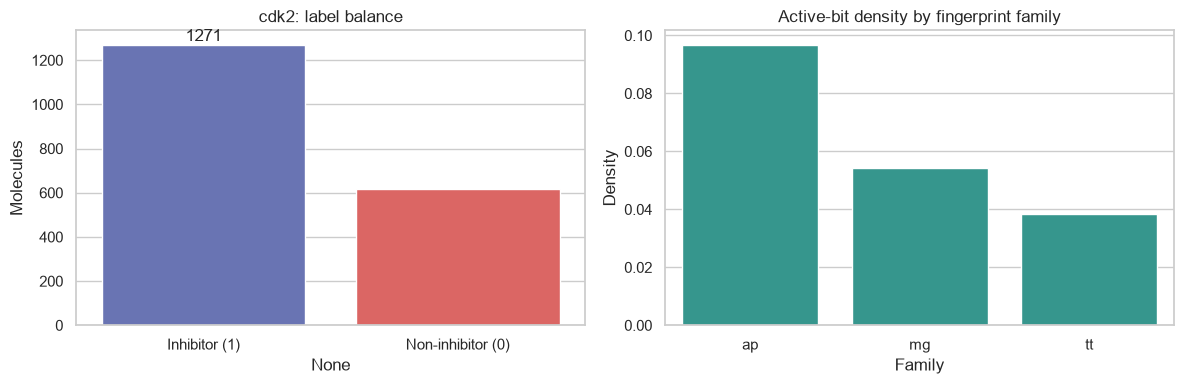

In [7]:
def savefig(name: str):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=180, bbox_inches="tight")
    plt.show()

# 1) Dataset audit and class distribution.
family_nnz = {name: int(X_sparse[:, sl].nnz) for name, sl in block_slices.items()}
packed = np.packbits((X > 0).astype(np.uint8), axis=1)
unique_rows = np.unique(packed, axis=0).shape[0]
audit = pd.DataFrame({
    "metric": ["samples", "features", "positive labels", "negative labels", "positive rate", "missing values", "exact duplicate vectors", "overall sparsity"],
    "value": [len(y), X.shape[1], int(y.sum()), int((y == 0).sum()), y.mean(), int(np.isnan(X).sum()), len(y) - unique_rows, 1 - X_sparse.nnz / X.size]
})
display(audit)

display(pd.DataFrame({
    "fingerprint_family": list(block_slices),
    "n_features": [sl.stop - sl.start for sl in block_slices.values()],
    "active_entries": [family_nnz[k] for k in block_slices],
    "density": [family_nnz[k] / (len(y) * (sl.stop - sl.start)) for k, sl in block_slices.items()]
}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
class_counts = pd.Series(y).map({0: "Non-inhibitor (0)", 1: "Inhibitor (1)"}).value_counts()
sns.barplot(x=class_counts.index, y=class_counts.values, palette=[PALETTE[0], PALETTE[1]], ax=axes[0])
axes[0].bar_label(axes[0].containers[0])
axes[0].set_title(f"{TARGET}: label balance")
axes[0].set_ylabel("Molecules")

family_density = pd.DataFrame({
    "Family": list(block_slices),
    "Density": [family_nnz[k] / (len(y) * (sl.stop - sl.start)) for k, sl in block_slices.items()]
})
sns.barplot(data=family_density, x="Family", y="Density", color="#26A69A", ax=axes[1])
axes[1].set_title("Active-bit density by fingerprint family")
axes[1].set_ylim(bottom=0)
savefig("01_audit_and_class_balance.png")

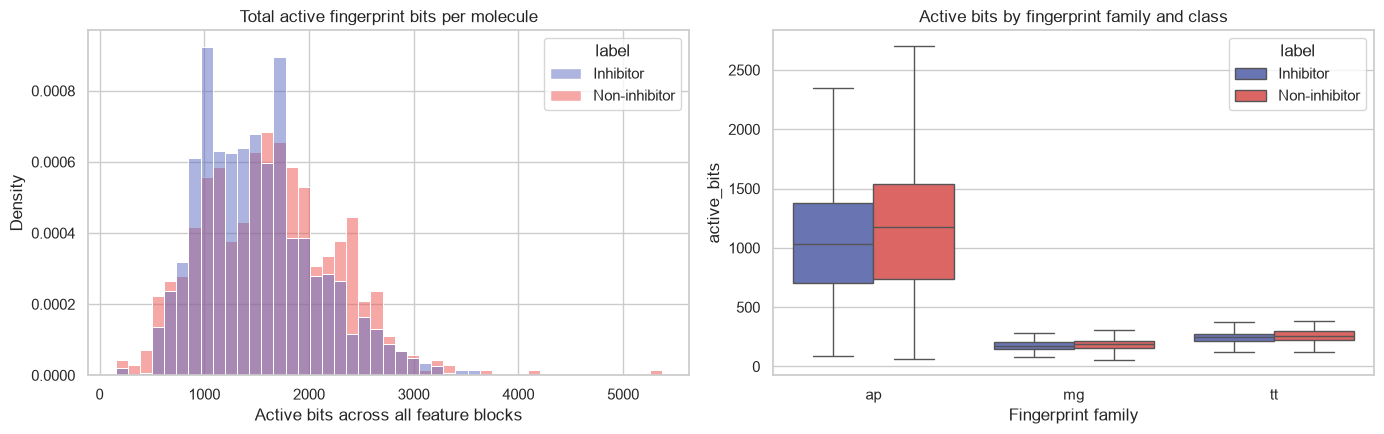

,statistic,active_bits_per_molecule
0,mean,1553.383545
1,median,1501.000000
2,std,590.681335
3,min,154.000000
4,max,5368.000000


In [8]:
# 2) Molecular fingerprint sparsity and activation distributions — stratified by label.
row_active = X.sum(axis=1)
family_active = pd.DataFrame({name: X[:, sl].sum(axis=1) for name, sl in block_slices.items()})
family_active["label"] = y

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=pd.DataFrame({"active_bits": row_active, "label": pd.Series(y).map({0: "Non-inhibitor", 1: "Inhibitor"})}),
             x="active_bits", hue="label", bins=45, stat="density", common_norm=False, palette=[PALETTE[0], PALETTE[1]], ax=axes[0])
axes[0].set_title("Total active fingerprint bits per molecule")
axes[0].set_xlabel("Active bits across all feature blocks")

family_long = family_active.melt(id_vars="label", var_name="family", value_name="active_bits")
family_long["label"] = family_long["label"].map({0: "Non-inhibitor", 1: "Inhibitor"})
sns.boxplot(data=family_long, x="family", y="active_bits", hue="label", palette=[PALETTE[0], PALETTE[1]], showfliers=False, ax=axes[1])
axes[1].set_title("Active bits by fingerprint family and class")
axes[1].set_xlabel("Fingerprint family")
savefig("02_sparsity_and_activation_distributions.png")

display(pd.DataFrame({
    "statistic": ["mean", "median", "std", "min", "max"],
    "active_bits_per_molecule": [row_active.mean(), np.median(row_active), row_active.std(), row_active.min(), row_active.max()]
}))

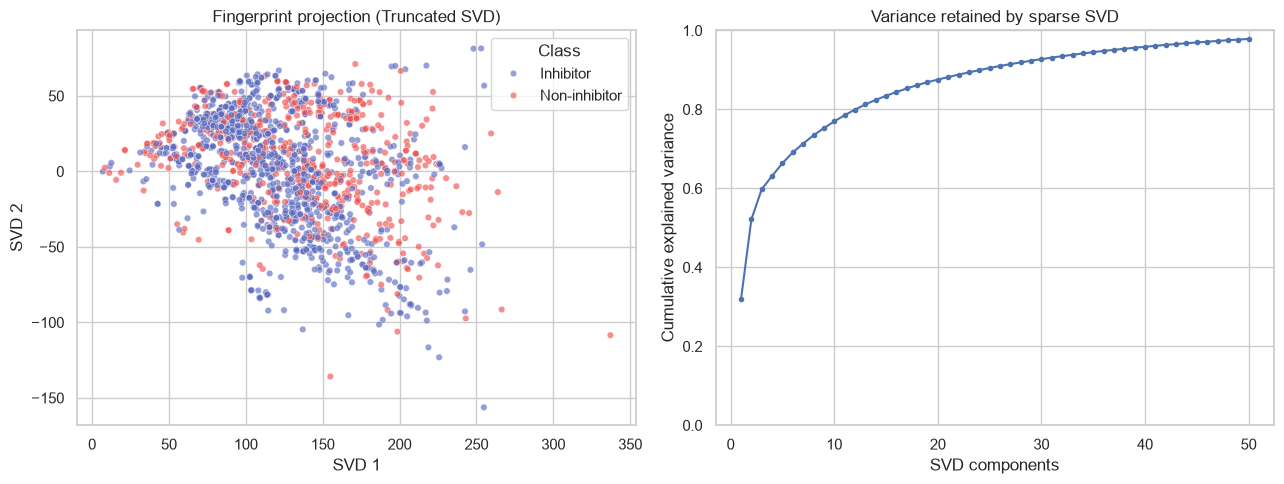

Computing mutual information for all fingerprint bits ...


,feature,mutual_information,prevalence_inhibitor,prevalence_non_inhibitor,prevalence_delta,family
0,fp_5565,0.115119,15.548388,21.017771,-5.469383,tt
1,fp_0396,0.091144,17.380016,20.505653,-3.125637,ap
2,fp_0397,0.089498,14.062156,17.392569,-3.330413,ap
3,fp_4564,0.086843,2.588513,2.523425,0.065088,tt
4,fp_4170,0.085889,14.933910,17.773829,-2.839918,tt
5,fp_5854,0.085169,15.551535,19.536348,-3.984814,tt
6,fp_0398,0.080139,11.003934,13.715671,-2.711737,ap
7,fp_1353,0.071974,23.582218,27.554119,-3.971901,ap
8,fp_0401,0.068384,9.536586,10.773829,-1.237243,ap
9,fp_0588,0.066714,2.929976,2.432956,0.497020,ap


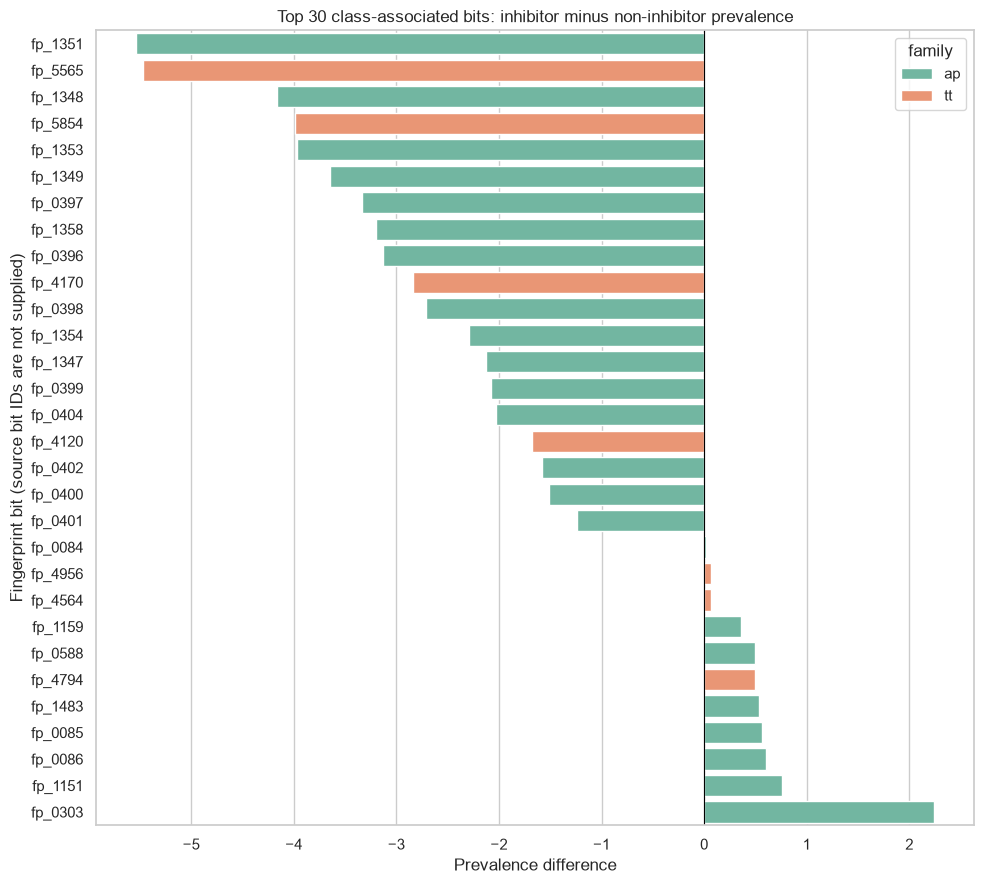

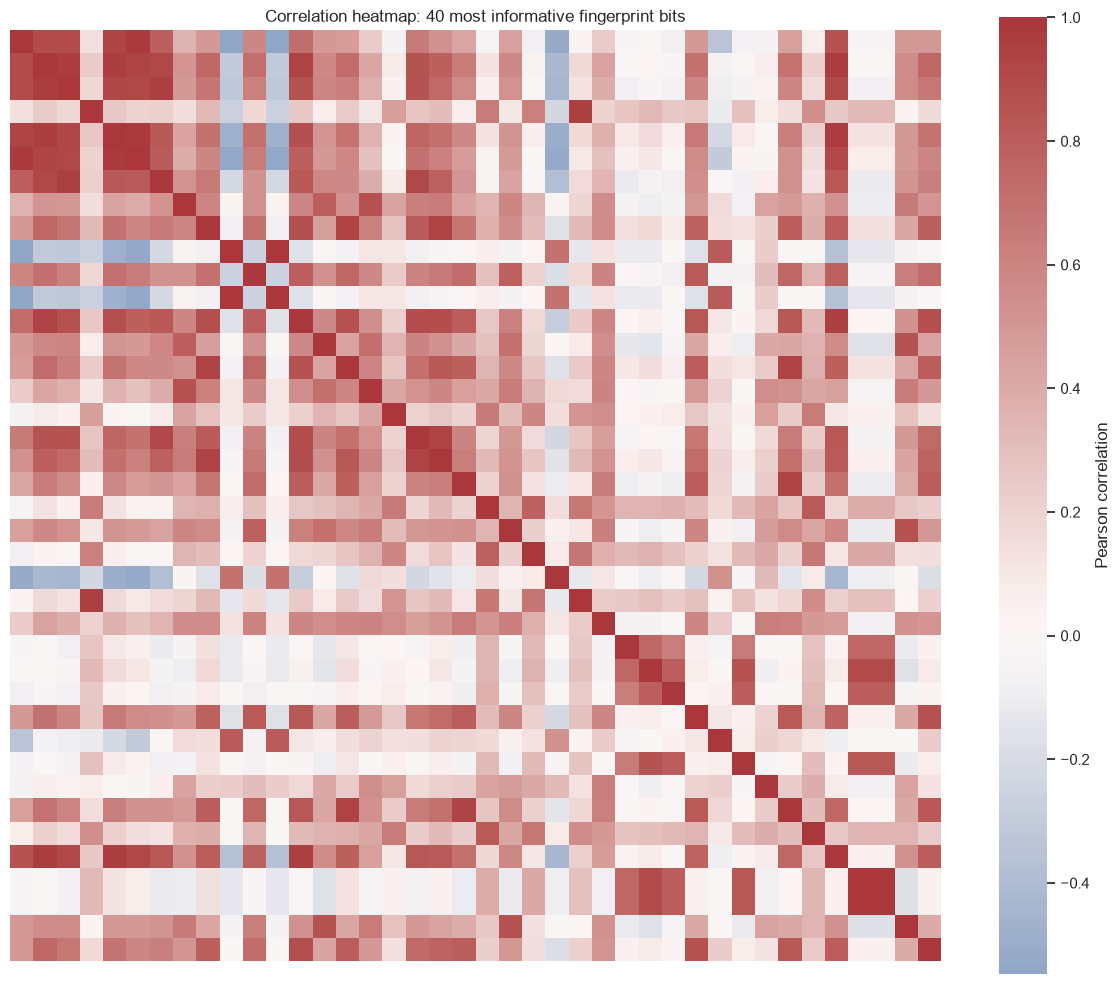

In [9]:
# 3) Low-dimensional view and top class-associated fingerprint bits.
# Truncated SVD accepts sparse input and is appropriate for sparse binary fingerprints.
svd = TruncatedSVD(n_components=min(50, X_sparse.shape[1] - 1), random_state=SEED)
X_svd = svd.fit_transform(X_sparse)
explained = svd.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_df = pd.DataFrame({"SVD 1": X_svd[:, 0], "SVD 2": X_svd[:, 1], "label": pd.Series(y).map({0: "Non-inhibitor", 1: "Inhibitor"})})
sns.scatterplot(data=plot_df, x="SVD 1", y="SVD 2", hue="label", palette=[PALETTE[0], PALETTE[1]], alpha=.65, s=22, ax=axes[0])
axes[0].set_title("Fingerprint projection (Truncated SVD)")
axes[0].legend(title="Class")
axes[1].plot(np.arange(1, len(explained) + 1), np.cumsum(explained), marker="o", ms=3)
axes[1].set(xlabel="SVD components", ylabel="Cumulative explained variance", title="Variance retained by sparse SVD", ylim=(0, 1))
savefig("03_svd_projection.png")

# Mutual information is non-negative; class prevalence difference adds direction.
print("Computing mutual information for all fingerprint bits ...")
mi = mutual_info_classif(X, y, discrete_features=True, random_state=SEED)
prev_pos = X[y == 1].mean(axis=0)
prev_neg = X[y == 0].mean(axis=0)
feature_stats = pd.DataFrame({
    "feature": feature_names,
    "mutual_information": mi,
    "prevalence_inhibitor": prev_pos,
    "prevalence_non_inhibitor": prev_neg,
})
feature_stats["prevalence_delta"] = feature_stats["prevalence_inhibitor"] - feature_stats["prevalence_non_inhibitor"]
feature_stats["family"] = np.select(
    [feature_stats.index.to_numpy() < sl.stop for sl in block_slices.values()],
    list(block_slices), default="other"
)
feature_stats = feature_stats.sort_values("mutual_information", ascending=False).reset_index(drop=True)
display(feature_stats.head(20))

plot_top = feature_stats.head(30).sort_values("prevalence_delta")
plt.figure(figsize=(10, 9))
sns.barplot(data=plot_top, x="prevalence_delta", y="feature", hue="family", dodge=False, palette="Set2")
plt.axvline(0, color="black", lw=0.8)
plt.title("Top 30 class-associated bits: inhibitor minus non-inhibitor prevalence")
plt.xlabel("Prevalence difference")
plt.ylabel("Fingerprint bit (source bit IDs are not supplied)")
savefig("04_top_feature_prevalence.png")

# Correlation is intentionally shown only for the most informative 40 bits.
top_corr_features = feature_stats.head(40)["feature"].tolist()
top_idx = [int(x.split("_")[1]) for x in top_corr_features]
corr = pd.DataFrame(X[:, top_idx], columns=top_corr_features).corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="vlag", center=0, xticklabels=False, yticklabels=False, square=True, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation heatmap: 40 most informative fingerprint bits")
savefig("05_selected_feature_correlation.png")

feature_stats.to_csv(OUTPUT_DIR / "all_feature_statistics.csv", index=False)

## Train/validation/test design

* The **test set is never used** for threshold selection, early stopping, or preprocessing choices.
* Stratification preserves the inhibitor/non-inhibitor ratio in each split.
* This is a random molecular split. For a stronger chemical-generalisation claim, replace it with a Bemis–Murcko scaffold split after obtaining SMILES; an optional scaffold split is not implemented from the supplied fingerprint-only data.
* Evaluation reports PR-AUC (especially useful for imbalance), ROC-AUC, balanced accuracy, F1, sensitivity/recall, precision, and MCC.

In [10]:
all_idx = np.arange(len(y))
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30, stratify=y, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=y[temp_idx], random_state=SEED)

X_train, X_val, X_test = X[train_idx], X[val_idx], X[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "n": [len(train_idx), len(val_idx), len(test_idx)],
    "inhibitors": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "inhibitor_rate": [y_train.mean(), y_val.mean(), y_test.mean()]
})
display(split_summary)
split_summary.to_csv(OUTPUT_DIR / "split_summary.csv", index=False)
np.savez(OUTPUT_DIR / "split_indices.npz", train=train_idx, validation=val_idx, test=test_idx)

# Validation-set threshold selection. It keeps the 0.5 default as a candidate and maximises F1 on validation only.
def select_threshold(y_true, probabilities):
    thresholds = np.unique(np.r_[0.05, np.linspace(0.10, 0.90, 161), 0.95])
    values = [f1_score(y_true, probabilities >= t, zero_division=0) for t in thresholds]
    return float(thresholds[int(np.argmax(values))])

def evaluate_probabilities(name, probabilities, threshold, y_true=y_test):
    pred = (np.asarray(probabilities) >= threshold).astype(int)
    return {
        "model": name,
        "threshold_from_validation": threshold,
        "ROC_AUC": roc_auc_score(y_true, probabilities),
        "PR_AUC": average_precision_score(y_true, probabilities),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "F1": f1_score(y_true, pred, zero_division=0),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall_sensitivity": recall_score(y_true, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_true, pred),
    }

results = []
test_scores = {}
thresholds = {}

,split,n,inhibitors,inhibitor_rate
0,train,1323,890,0.672714
1,validation,283,190,0.671378
2,test,284,191,0.672535


# Classical baselines

These models are important controls. For sparse molecular fingerprints, regularised linear and tree-ensemble models are often strong and substantially easier to audit than neural networks. Class weighting is learned from the training split only.

In [11]:
# `saga` handles high-dimensional binary features; Extra Trees captures non-linear feature interactions.
class_weight = "balanced"
classical_models = {
    "Logistic regression": Pipeline([
        ("model", LogisticRegression(
            solver="saga", penalty="l2", C=1.0, max_iter=2500,
            class_weight=class_weight, random_state=SEED, n_jobs=-1
        ))
    ]),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=N_TREES, max_features="sqrt", min_samples_leaf=2,
        class_weight=class_weight, random_state=SEED, n_jobs=-1
    ),
}

fitted_models = {}
for name, model in classical_models.items():
    print(f"Fitting {name} ...")
    model.fit(X_train, y_train)
    val_prob = model.predict_proba(X_val)[:, 1]
    threshold = select_threshold(y_val, val_prob)
    test_prob = model.predict_proba(X_test)[:, 1]
    fitted_models[name] = model
    thresholds[name] = threshold
    test_scores[name] = test_prob
    results.append(evaluate_probabilities(name, test_prob, threshold))
    joblib.dump(model, OUTPUT_DIR / f"{name.lower().replace(' ', '_')}.joblib")

results_df = pd.DataFrame(results).sort_values("PR_AUC", ascending=False)
display(results_df.style.format(precision=3))
results_df.to_csv(OUTPUT_DIR / "test_metrics_classical.csv", index=False)

Fitting Logistic regression ...


C:\Users\MANO\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Fitting Extra Trees ...


,model,threshold_from_validation,ROC_AUC,PR_AUC,balanced_accuracy,F1,precision,recall_sensitivity,MCC
1,Extra Trees,0.440,0.933,0.966,0.816,0.890,0.870,0.911,0.649
0,Logistic regression,0.430,0.894,0.917,0.832,0.900,0.880,0.921,0.682


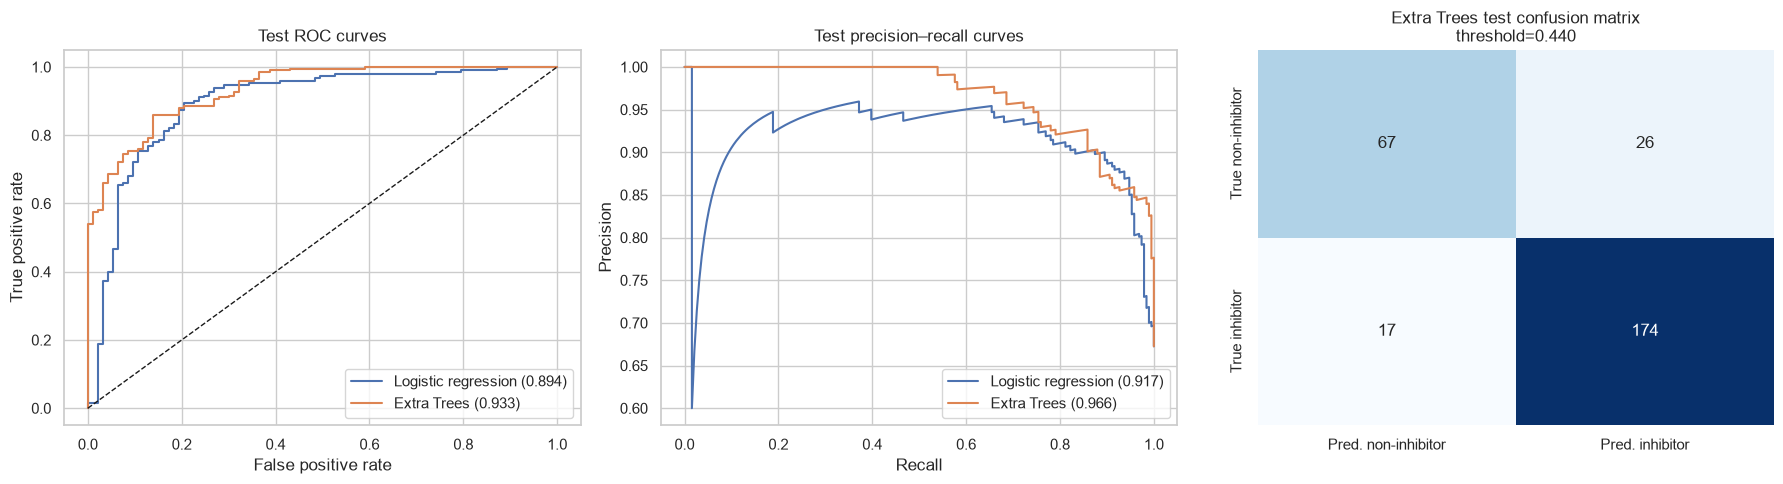

In [12]:
# Classical test-set diagnostic plots.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name, score in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    p, r, _ = precision_recall_curve(y_test, score)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, score):.3f})")
    axes[1].plot(r, p, label=f"{name} ({average_precision_score(y_test, score):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="Test ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Test precision–recall curves", xlabel="Recall", ylabel="Precision")
axes[0].legend(); axes[1].legend()

best_classical = results_df.iloc[0]["model"]
cm = confusion_matrix(y_test, test_scores[best_classical] >= thresholds[best_classical])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[2],
            xticklabels=["Pred. non-inhibitor", "Pred. inhibitor"], yticklabels=["True non-inhibitor", "True inhibitor"])
axes[2].set_title(f"{best_classical} test confusion matrix\nthreshold={thresholds[best_classical]:.3f}")
savefig("06_classical_model_diagnostics.png")

# Self-supervised pre-training on fingerprint vectors

The Kaggle feature files do not contain a portable externally pre-trained encoder. To create a valid transfer-learning baseline without leaking the validation/test data, the next model pre-trains a **masked fingerprint autoencoder using `X_train` only and without labels**. It must reconstruct randomly hidden fingerprint bits. We then compare:

1. **Frozen linear probe:** encoder fixed, only a classifier head learns labels.
2. **Fine-tuned transfer model:** same pre-trained encoder, then all layers adapt to labels.

These are *self-supervised pre-trained models*, not equivalent to a chemical foundation model trained on an external corpus. The later optional ChemBERTa section is the genuine foundation-model alternative when SMILES can be retrieved.

Using device: cpu
Pre-train epoch 01/25: masked reconstruction loss=0.15309
Pre-train epoch 02/25: masked reconstruction loss=-39.32567
Pre-train epoch 03/25: masked reconstruction loss=-495.62996
Pre-train epoch 04/25: masked reconstruction loss=-2997.59136
Pre-train epoch 05/25: masked reconstruction loss=-12208.64539
Pre-train epoch 06/25: masked reconstruction loss=-39651.74910
Pre-train epoch 07/25: masked reconstruction loss=-105992.60431
Pre-train epoch 08/25: masked reconstruction loss=-247128.51967
Pre-train epoch 09/25: masked reconstruction loss=-525031.84601
Pre-train epoch 10/25: masked reconstruction loss=-1002711.42419
Pre-train epoch 11/25: masked reconstruction loss=-1794781.89584
Pre-train epoch 12/25: masked reconstruction loss=-3090477.73766
Pre-train epoch 13/25: masked reconstruction loss=-5067928.93210
Pre-train epoch 14/25: masked reconstruction loss=-8145651.81495
Pre-train epoch 15/25: masked reconstruction loss=-12423509.58214
Pre-train epoch 16/25: masked re

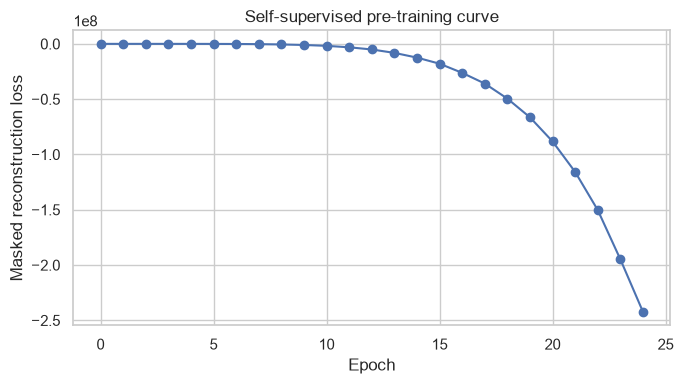

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

# Loaders contain only data appropriate to each stage.
def fp_loader(x, y_values=None, shuffle=False, batch_size=BATCH_SIZE):
    x_tensor = torch.tensor(x, dtype=torch.float32)
    if y_values is None:
        ds = TensorDataset(x_tensor)
    else:
        ds = TensorDataset(x_tensor, torch.tensor(y_values, dtype=torch.float32))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=0, pin_memory=(DEVICE.type == "cuda"))

train_unsup_loader = fp_loader(X_train, shuffle=True)
train_loader = fp_loader(X_train, y_train, shuffle=True)
val_loader = fp_loader(X_val, y_val)
test_loader = fp_loader(X_test, y_test)

class MaskedFingerprintAutoencoder(nn.Module):
    def __init__(self, n_features, latent_dim=256):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(n_features, 1024), nn.BatchNorm1d(1024), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(1024, 512), nn.BatchNorm1d(512), nn.GELU(),
            nn.Linear(512, latent_dim), nn.GELU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 512), nn.GELU(), nn.Dropout(0.10),
            nn.Linear(512, 1024), nn.GELU(), nn.Linear(1024, n_features),
        )
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

# Use a bounded positive weight because active bits are sparse and all-zero reconstruction is uninformative.
active_rate = float(X_train.mean())
bit_pos_weight = torch.tensor(min(25.0, (1 - active_rate) / max(active_rate, 1e-6)), device=DEVICE)
autoencoder = MaskedFingerprintAutoencoder(X.shape[1]).to(DEVICE)
optimizer = torch.optim.AdamW(autoencoder.parameters(), lr=1e-3, weight_decay=1e-5)
pretrain_history = []

for epoch in range(1, AE_EPOCHS + 1):
    autoencoder.train()
    running_loss, masked_count = 0.0, 0
    for (xb,) in train_unsup_loader:
        xb = xb.to(DEVICE)
        # Hide 15% of bits. Loss is measured only at the hidden positions.
        mask = torch.rand_like(xb) < 0.15
        x_masked = xb.masked_fill(mask, 0.0)
        reconstruction_logits, _ = autoencoder(x_masked)
        element_loss = F.binary_cross_entropy_with_logits(reconstruction_logits, xb, reduction="none", pos_weight=bit_pos_weight)
        loss = (element_loss * mask).sum() / mask.sum().clamp_min(1)
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        running_loss += float(loss.detach()) * int(mask.sum())
        masked_count += int(mask.sum())
    epoch_loss = running_loss / max(masked_count, 1)
    pretrain_history.append(epoch_loss)
    print(f"Pre-train epoch {epoch:02d}/{AE_EPOCHS}: masked reconstruction loss={epoch_loss:.5f}")

plt.figure(figsize=(7, 4))
plt.plot(pretrain_history, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Masked reconstruction loss"); plt.title("Self-supervised pre-training curve")
savefig("07_autoencoder_pretraining.png")
torch.save(autoencoder.state_dict(), OUTPUT_DIR / "masked_fingerprint_autoencoder.pt")

Frozen transfer probe | epoch 01/30: loss=13.8855; val PR-AUC=0.6713
Frozen transfer probe | epoch 02/30: loss=7.3846; val PR-AUC=0.6415
Frozen transfer probe | epoch 03/30: loss=8.4215; val PR-AUC=0.7136
Frozen transfer probe | epoch 04/30: loss=5.5059; val PR-AUC=0.6416
Frozen transfer probe | epoch 05/30: loss=5.0718; val PR-AUC=0.7085
Frozen transfer probe | epoch 06/30: loss=2.1475; val PR-AUC=0.6802
Frozen transfer probe | epoch 07/30: loss=1.1949; val PR-AUC=0.6587
Frozen transfer probe | epoch 08/30: loss=0.6930; val PR-AUC=0.7220
Frozen transfer probe | epoch 09/30: loss=0.4612; val PR-AUC=0.7271
Frozen transfer probe | epoch 10/30: loss=0.4545; val PR-AUC=0.7087
Frozen transfer probe | epoch 11/30: loss=0.4501; val PR-AUC=0.7076
Frozen transfer probe | epoch 12/30: loss=0.4528; val PR-AUC=0.7075
Frozen transfer probe | epoch 13/30: loss=0.4525; val PR-AUC=0.7050
Frozen transfer probe | epoch 14/30: loss=0.4548; val PR-AUC=0.7082
Frozen transfer probe | epoch 15/30: loss=0.453

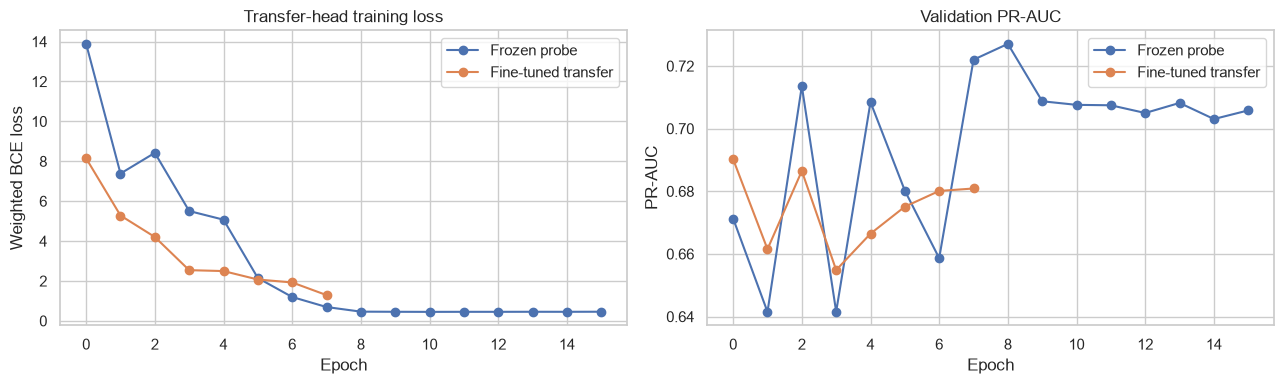

In [14]:
# Shared routines for transfer heads and the CNN.
positive_weight = torch.tensor([(len(y_train) - y_train.sum()) / max(y_train.sum(), 1)], dtype=torch.float32, device=DEVICE)

def predict_torch(model, loader):
    model.eval()
    probs, actual = [], []
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb.to(DEVICE)).squeeze(1)
            probs.extend(torch.sigmoid(logits).cpu().numpy())
            actual.extend(yb.numpy())
    return np.asarray(probs), np.asarray(actual).astype(int)

def train_binary_torch(model, train_loader, valid_loader, epochs, lr=1e-3, name="model"):
    model = model.to(DEVICE)
    optimizer = torch.optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=lr, weight_decay=1e-5)
    criterion = nn.BCEWithLogitsLoss(pos_weight=positive_weight)
    best_state, best_ap = None, -np.inf
    history = {"train_loss": [], "val_pr_auc": []}
    patience, waited = 7, 0
    for epoch in range(1, epochs + 1):
        model.train()
        # Frozen encoders should keep their batch-normalisation statistics frozen.
        if hasattr(model, "encoder_frozen") and model.encoder_frozen:
            model.encoder.eval()
        losses = []
        for xb, yb in train_loader:
            logits = model(xb.to(DEVICE)).squeeze(1)
            loss = criterion(logits, yb.to(DEVICE))
            optimizer.zero_grad(); loss.backward(); optimizer.step()
            losses.append(float(loss.detach()))
        val_prob, val_actual = predict_torch(model, valid_loader)
        val_ap = average_precision_score(val_actual, val_prob)
        history["train_loss"].append(np.mean(losses)); history["val_pr_auc"].append(val_ap)
        if val_ap > best_ap + 1e-4:
            best_ap, best_state, waited = val_ap, deepcopy(model.state_dict()), 0
        else:
            waited += 1
        print(f"{name} | epoch {epoch:02d}/{epochs}: loss={np.mean(losses):.4f}; val PR-AUC={val_ap:.4f}")
        if waited >= patience:
            print(f"Early stopping {name} at epoch {epoch}; best validation PR-AUC={best_ap:.4f}")
            break
    model.load_state_dict(best_state)
    return model, history

class TransferFingerprintClassifier(nn.Module):
    def __init__(self, pretrained_encoder, latent_dim=256, freeze_encoder=True):
        super().__init__()
        self.encoder = deepcopy(pretrained_encoder)
        self.encoder_frozen = freeze_encoder
        if freeze_encoder:
            for p in self.encoder.parameters():
                p.requires_grad = False
        self.head = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.GELU(), nn.Dropout(0.20), nn.Linear(128, 1)
        )
    def forward(self, x):
        z = self.encoder(x)
        return self.head(z)

# Model 1: labelled linear/nonlinear probe with the encoder frozen.
frozen_probe = TransferFingerprintClassifier(autoencoder.encoder, freeze_encoder=True)
frozen_probe, frozen_history = train_binary_torch(frozen_probe, train_loader, val_loader, HEAD_EPOCHS, lr=2e-3, name="Frozen transfer probe")

# Model 2: same self-supervised pre-training, then end-to-end supervised adaptation.
finetuned_transfer = TransferFingerprintClassifier(autoencoder.encoder, freeze_encoder=False)
finetuned_transfer, finetune_history = train_binary_torch(finetuned_transfer, train_loader, val_loader, HEAD_EPOCHS, lr=5e-4, name="Fine-tuned transfer")

transfer_models = {
    "Frozen transfer probe": frozen_probe,
    "Fine-tuned transfer": finetuned_transfer,
}
for name, model in transfer_models.items():
    val_prob, _ = predict_torch(model, val_loader)
    test_prob, _ = predict_torch(model, test_loader)
    threshold = select_threshold(y_val, val_prob)
    thresholds[name] = threshold
    test_scores[name] = test_prob
    results.append(evaluate_probabilities(name, test_prob, threshold))
    torch.save(model.state_dict(), OUTPUT_DIR / f"{name.lower().replace(' ', '_').replace('-', '_')}.pt")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for title, hist in [("Frozen probe", frozen_history), ("Fine-tuned transfer", finetune_history)]:
    axes[0].plot(hist["train_loss"], marker="o", label=title)
    axes[1].plot(hist["val_pr_auc"], marker="o", label=title)
axes[0].set(title="Transfer-head training loss", xlabel="Epoch", ylabel="Weighted BCE loss")
axes[1].set(title="Validation PR-AUC", xlabel="Epoch", ylabel="PR-AUC")
axes[0].legend(); axes[1].legend()
savefig("08_transfer_learning_curves.png")

# Pure CNN trained from scratch

This CNN receives only the fingerprint vector and starts with random weights — no transferred representation. It is included as a controlled deep-learning comparison. Since neighbouring fingerprint columns are not necessarily chemically neighbouring features, do **not** interpret convolutional locality as molecular spatial locality.

Pure 1-D CNN | epoch 01/35: loss=1.0510; val PR-AUC=0.7037
Pure 1-D CNN | epoch 02/35: loss=0.5389; val PR-AUC=0.7164
Pure 1-D CNN | epoch 03/35: loss=0.4901; val PR-AUC=0.7366
Pure 1-D CNN | epoch 04/35: loss=0.4579; val PR-AUC=0.7610
Pure 1-D CNN | epoch 05/35: loss=0.4376; val PR-AUC=0.7724
Pure 1-D CNN | epoch 06/35: loss=0.4230; val PR-AUC=0.7765
Pure 1-D CNN | epoch 07/35: loss=0.4264; val PR-AUC=0.7804
Pure 1-D CNN | epoch 11/35: loss=0.4132; val PR-AUC=0.7930
Pure 1-D CNN | epoch 12/35: loss=0.3977; val PR-AUC=0.7956
Pure 1-D CNN | epoch 13/35: loss=0.4041; val PR-AUC=0.8010
Pure 1-D CNN | epoch 14/35: loss=0.4023; val PR-AUC=0.7968
Pure 1-D CNN | epoch 15/35: loss=0.3948; val PR-AUC=0.7915
Pure 1-D CNN | epoch 16/35: loss=0.3932; val PR-AUC=0.8123
Pure 1-D CNN | epoch 17/35: loss=0.3875; val PR-AUC=0.8164
Pure 1-D CNN | epoch 18/35: loss=0.3957; val PR-AUC=0.8107
Pure 1-D CNN | epoch 19/35: loss=0.3803; val PR-AUC=0.8086
Pure 1-D CNN | epoch 20/35: loss=0.3674; val PR-AUC=0.82

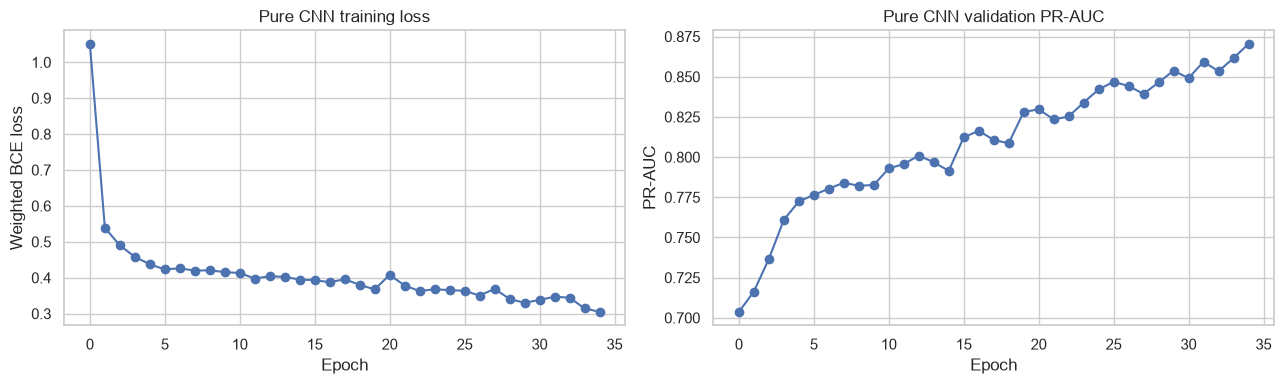

In [15]:
class PureFingerprintCNN(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 64, kernel_size=9, padding=4), nn.BatchNorm1d(64), nn.GELU(),
            nn.MaxPool1d(2), nn.Dropout(0.10),
            nn.Conv1d(64, 128, kernel_size=7, padding=3), nn.BatchNorm1d(128), nn.GELU(),
            nn.MaxPool1d(2), nn.Dropout(0.15),
            nn.Conv1d(128, 256, kernel_size=5, padding=2), nn.BatchNorm1d(256), nn.GELU(),
            nn.AdaptiveMaxPool1d(1),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(256, 128), nn.GELU(), nn.Dropout(0.25), nn.Linear(128, 1))
    def forward(self, x):
        return self.classifier(self.features(x.unsqueeze(1)))

pure_cnn = PureFingerprintCNN(X.shape[1])
pure_cnn, cnn_history = train_binary_torch(pure_cnn, train_loader, val_loader, CNN_EPOCHS, lr=8e-4, name="Pure 1-D CNN")

cnn_val_prob, _ = predict_torch(pure_cnn, val_loader)
cnn_test_prob, _ = predict_torch(pure_cnn, test_loader)
cnn_name = "Pure 1-D CNN"
thresholds[cnn_name] = select_threshold(y_val, cnn_val_prob)
test_scores[cnn_name] = cnn_test_prob
results.append(evaluate_probabilities(cnn_name, cnn_test_prob, thresholds[cnn_name]))
torch.save(pure_cnn.state_dict(), OUTPUT_DIR / "pure_1d_cnn.pt")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(cnn_history["train_loss"], marker="o")
axes[0].set(title="Pure CNN training loss", xlabel="Epoch", ylabel="Weighted BCE loss")
axes[1].plot(cnn_history["val_pr_auc"], marker="o")
axes[1].set(title="Pure CNN validation PR-AUC", xlabel="Epoch", ylabel="PR-AUC")
savefig("09_pure_cnn_learning_curves.png")

# Optional: fine-tune a real pre-trained molecular foundation model (ChemBERTa)

**Why optional?** ChemBERTa needs SMILES, but the supplied Kaggle HDF5 records only identify compounds through ChEMBL IDs. This cell retrieves canonical SMILES from the public ChEMBL API, caching every successful response, then fine-tunes `seyonec/ChemBERTa-zinc-base-v1` on a stratified subset of each existing split.

Enable `RUN_CHEMBERTA=True` only with Internet access and preferably a GPU. This approach is chemically more appropriate than treating fingerprint positions as pixels, but it is limited by missing/unresolvable structures and should use a scaffold split for a publication-grade estimate.

In [16]:
if RUN_CHEMBERTA:
    # %pip install -q transformers accelerate requests
    import requests
    from torch.utils.data import Dataset
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    CHEMBERTA_MODEL = "seyonec/ChemBERTa-zinc-base-v1"
    MAX_CHEMBERTA_PER_SPLIT = 1200 if not FAST_RUN else 250
    SMILES_CACHE = OUTPUT_DIR / "chembl_smiles_cache.json"
    cache = json.loads(SMILES_CACHE.read_text()) if SMILES_CACHE.exists() else {}

    def sample_split_indices(indices, labels, n_max):
        """Return an approximately stratified subset, retaining both classes."""
        if len(indices) <= n_max:
            return np.asarray(indices)
        chosen, rng = [], np.random.default_rng(SEED)
        for cls in (0, 1):
            members = np.asarray(indices)[labels[indices] == cls]
            take = max(1, round(n_max * len(members) / len(indices)))
            chosen.extend(rng.choice(members, min(take, len(members)), replace=False))
        return np.asarray(chosen[:n_max])

    chem_train_idx = sample_split_indices(train_idx, y, MAX_CHEMBERTA_PER_SPLIT)
    chem_val_idx = sample_split_indices(val_idx, y, MAX_CHEMBERTA_PER_SPLIT)
    chem_test_idx = sample_split_indices(test_idx, y, MAX_CHEMBERTA_PER_SPLIT)
    chem_indices = np.unique(np.r_[chem_train_idx, chem_val_idx, chem_test_idx])

    def chembl_smiles(chembl_id):
        chembl_id = str(chembl_id)
        if chembl_id in cache:
            return cache[chembl_id]
        try:
            response = requests.get(
                f"https://www.ebi.ac.uk/chembl/api/data/molecule/{chembl_id}.json",
                timeout=20,
                headers={"Accept": "application/json"},
            )
            response.raise_for_status()
            payload = response.json()
            smiles = (payload.get("molecule_structures") or {}).get("canonical_smiles")
        except Exception:
            smiles = None
        cache[chembl_id] = smiles
        return smiles

    smiles_by_idx = {}
    for idx in tqdm(chem_indices, desc="Retrieving/caching ChEMBL SMILES"):
        value = chembl_smiles(molecule_ids[idx])
        if value:
            smiles_by_idx[int(idx)] = value
    SMILES_CACHE.write_text(json.dumps(cache, indent=2))

    def valid_indices(indices):
        return np.asarray([i for i in indices if int(i) in smiles_by_idx])
    chem_train_idx, chem_val_idx, chem_test_idx = map(valid_indices, [chem_train_idx, chem_val_idx, chem_test_idx])
    print("Resolved SMILES by split:", {"train": len(chem_train_idx), "val": len(chem_val_idx), "test": len(chem_test_idx)})
    if min(len(chem_train_idx), len(chem_val_idx), len(chem_test_idx)) == 0:
        raise RuntimeError("No SMILES resolved in a split. Check Internet access and ChEMBL ID format.")

    tokenizer = AutoTokenizer.from_pretrained(CHEMBERTA_MODEL)
    class SmilesDataset(Dataset):
        def __init__(self, indices):
            self.indices = np.asarray(indices)
        def __len__(self): return len(self.indices)
        def __getitem__(self, j):
            idx = int(self.indices[j])
            encoded = tokenizer(smiles_by_idx[idx], truncation=True, max_length=256, padding="max_length", return_tensors="pt")
            return {"input_ids": encoded["input_ids"].squeeze(0), "attention_mask": encoded["attention_mask"].squeeze(0), "label": torch.tensor(y[idx], dtype=torch.long)}

    def collate_smiles(batch):
        return {key: torch.stack([x[key] for x in batch]) for key in batch[0]}

    chem_train_loader = DataLoader(SmilesDataset(chem_train_idx), batch_size=16, shuffle=True, collate_fn=collate_smiles)
    chem_val_loader = DataLoader(SmilesDataset(chem_val_idx), batch_size=32, shuffle=False, collate_fn=collate_smiles)
    chem_test_loader = DataLoader(SmilesDataset(chem_test_idx), batch_size=32, shuffle=False, collate_fn=collate_smiles)
    chemberta = AutoModelForSequenceClassification.from_pretrained(CHEMBERTA_MODEL, num_labels=2, ignore_mismatched_sizes=True).to(DEVICE)
    optimizer = torch.optim.AdamW(chemberta.parameters(), lr=2e-5)
    class_weights = torch.tensor(compute_class_weight("balanced", classes=np.array([0, 1]), y=y[chem_train_idx]), dtype=torch.float32, device=DEVICE)

    def chem_probs(model, loader):
        model.eval(); out_prob, out_y = [], []
        with torch.no_grad():
            for batch in loader:
                logits = model(input_ids=batch["input_ids"].to(DEVICE), attention_mask=batch["attention_mask"].to(DEVICE)).logits
                out_prob.extend(torch.softmax(logits, 1)[:, 1].cpu().numpy())
                out_y.extend(batch["label"].numpy())
        return np.asarray(out_prob), np.asarray(out_y)

    best_state, best_ap, wait = None, -np.inf, 0
    for epoch in range(1, (2 if FAST_RUN else 4) + 1):
        chemberta.train(); losses = []
        for batch in chem_train_loader:
            logits = chemberta(input_ids=batch["input_ids"].to(DEVICE), attention_mask=batch["attention_mask"].to(DEVICE)).logits
            loss = F.cross_entropy(logits, batch["label"].to(DEVICE), weight=class_weights)
            optimizer.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(chemberta.parameters(), 1.0); optimizer.step()
            losses.append(float(loss.detach()))
        val_prob, val_y = chem_probs(chemberta, chem_val_loader)
        ap = average_precision_score(val_y, val_prob)
        print(f"ChemBERTa epoch {epoch}: train loss={np.mean(losses):.4f}, val PR-AUC={ap:.4f}")
        if ap > best_ap:
            best_ap, best_state, wait = ap, deepcopy(chemberta.state_dict()), 0
        else:
            wait += 1
            if wait >= 2: break
    chemberta.load_state_dict(best_state)
    chem_val_prob, chem_val_y = chem_probs(chemberta, chem_val_loader)
    chem_test_prob, chem_test_y = chem_probs(chemberta, chem_test_loader)
    chem_threshold = select_threshold(chem_val_y, chem_val_prob)
    chem_name = "Pre-trained ChemBERTa (SMILES subset)"
    chem_metrics = evaluate_probabilities(chem_name, chem_test_prob, chem_threshold, y_true=chem_test_y)
    display(pd.DataFrame([chem_metrics]).style.format(precision=3))
    torch.save(chemberta.state_dict(), OUTPUT_DIR / "chemberta_finetuned.pt")
else:
    print("ChemBERTa skipped. Set RUN_CHEMBERTA=True in the configuration cell to retrieve SMILES and fine-tune it.")

ChemBERTa skipped. Set RUN_CHEMBERTA=True in the configuration cell to retrieve SMILES and fine-tune it.


# Quantum Machine Learning (QML): variational quantum classifier

This section benchmarks a **variational quantum classifier (VQC)** with PennyLane. Quantum simulators cannot accept 6,117 fingerprint features directly, so the pipeline is deliberately constrained and leakage-safe:

1. Rank fingerprint bits by mutual information using **only the training split**.
2. Retain the `QML_N_QUBITS` most associated bits and scale them to rotation angles in $[-\pi, \pi]$ using the training data only.
3. Train an angle-embedding, strongly-entangling quantum circuit on a class-balanced capped training subset; retain the full validation and test sets for assessment.
4. Choose the classification threshold only on validation data.

> **Interpretation:** This is a reproducible QML benchmark on a state-vector simulator, not evidence of quantum advantage. Dimension reduction can discard relevant chemical features, and NISQ hardware noise, data loading, and shot budgets are not modelled by the default analytic simulator. Compare the VQC with the classical baselines rather than assuming it will perform better.


In [18]:
%pip install -q "pennylane>=0.36,<1.0"

Note: you may need to restart the kernel to use updated packages.


,qml_wire,original_feature_index,fingerprint_bit,train_mutual_information
0,0,396,fp_0396,0.098863
1,1,397,fp_0397,0.104835
2,2,1353,fp_1353,0.085833
3,3,1354,fp_1354,0.085291
4,4,4170,fp_4170,0.087600
5,5,4564,fp_4564,0.096798
6,6,5565,fp_5565,0.125112
7,7,5854,fp_5854,0.088696


QML training samples: 933; qubits: 8; layers: 2
QML epoch 01/25: loss=0.6876; val PR-AUC=0.7652
QML epoch 02/25: loss=0.6613; val PR-AUC=0.7813
QML epoch 03/25: loss=0.6357; val PR-AUC=0.7858
QML epoch 04/25: loss=0.6262; val PR-AUC=0.7915
QML epoch 05/25: loss=0.6182; val PR-AUC=0.7881
QML epoch 06/25: loss=0.6163; val PR-AUC=0.7928
QML epoch 07/25: loss=0.6154; val PR-AUC=0.7922
QML epoch 08/25: loss=0.6058; val PR-AUC=0.7950
QML epoch 09/25: loss=0.6061; val PR-AUC=0.8002
QML epoch 10/25: loss=0.6063; val PR-AUC=0.7930
QML epoch 11/25: loss=0.6093; val PR-AUC=0.7865
QML epoch 12/25: loss=0.6016; val PR-AUC=0.7866
QML epoch 13/25: loss=0.6030; val PR-AUC=0.7946
QML epoch 14/25: loss=0.6046; val PR-AUC=0.8002
QML epoch 15/25: loss=0.5956; val PR-AUC=0.8071
QML epoch 16/25: loss=0.6022; val PR-AUC=0.8115
QML epoch 17/25: loss=0.6017; val PR-AUC=0.8222
QML epoch 18/25: loss=0.5946; val PR-AUC=0.8255
QML epoch 19/25: loss=0.5894; val PR-AUC=0.8267
QML epoch 20/25: loss=0.5981; val PR-AUC

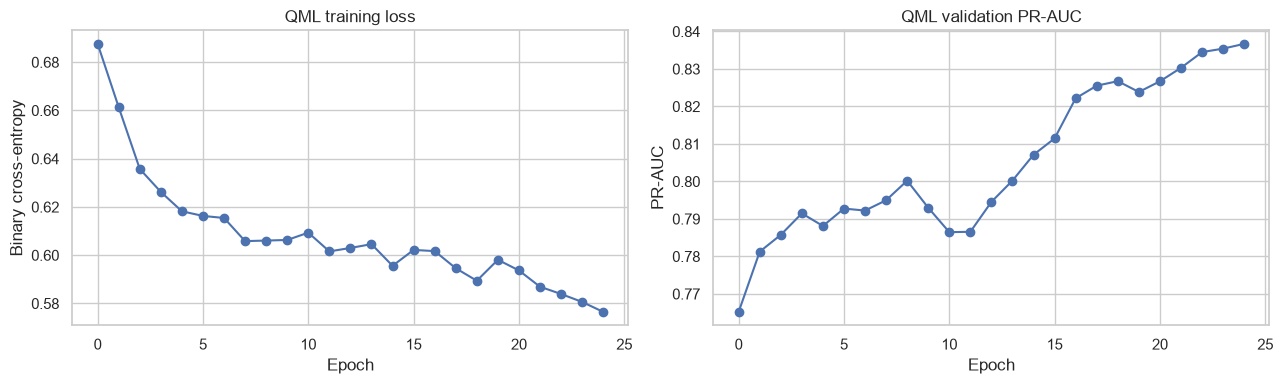

In [19]:
if RUN_QML:
    # Install once if PennyLane is not already installed:
    # %pip install -q "pennylane>=0.36,<1.0"
    try:
        import pennylane as qml
    except ImportError as exc:
        raise ImportError(
            "PennyLane is required for QML. Run: pip install 'pennylane>=0.36,<1.0'"
        ) from exc

    from sklearn.feature_selection import SelectKBest
    from sklearn.preprocessing import MinMaxScaler

    def training_mutual_information(x_values, labels):
        # QML feature selection is fitted on training data only.
        return mutual_info_classif(
            x_values, labels, discrete_features=True, random_state=SEED
        )

    # Train-only supervised feature selection and scaling to quantum rotation angles.
    qml_selector = SelectKBest(score_func=training_mutual_information, k=QML_N_QUBITS)
    Xq_train_full = qml_selector.fit_transform(X_train, y_train).astype(np.float32)
    Xq_val = qml_selector.transform(X_val).astype(np.float32)
    Xq_test = qml_selector.transform(X_test).astype(np.float32)
    qml_selected_original_idx = qml_selector.get_support(indices=True)

    # AngleEmbedding uses rotation angles. The scaler does not inspect validation or test data.
    qml_scaler = MinMaxScaler(feature_range=(-np.pi, np.pi), clip=True)
    Xq_train_full = qml_scaler.fit_transform(Xq_train_full).astype(np.float32)
    Xq_val = qml_scaler.transform(Xq_val).astype(np.float32)
    Xq_test = qml_scaler.transform(Xq_test).astype(np.float32)

    qml_feature_map = pd.DataFrame({
        "qml_wire": np.arange(QML_N_QUBITS),
        "original_feature_index": qml_selected_original_idx,
        "fingerprint_bit": feature_names[qml_selected_original_idx],
        "train_mutual_information": qml_selector.scores_[qml_selected_original_idx],
    }).sort_values("qml_wire")
    display(qml_feature_map)
    qml_feature_map.to_csv(OUTPUT_DIR / "qml_selected_fingerprint_features.csv", index=False)

    def balanced_local_subset(labels, cap_per_class, random_state=SEED):
        """Class-balanced local row indices for simulator-feasible QML training."""
        rng = np.random.default_rng(random_state)
        chosen = []
        for cls in (0, 1):
            available = np.flatnonzero(labels == cls)
            if len(available) == 0:
                raise ValueError(f"QML training data has no examples for class {cls}.")
            chosen.extend(rng.choice(available, min(cap_per_class, len(available)), replace=False))
        return np.asarray(chosen, dtype=int)

    qml_train_local_idx = balanced_local_subset(y_train, QML_TRAIN_PER_CLASS)
    rng = np.random.default_rng(SEED)
    rng.shuffle(qml_train_local_idx)
    Xq_train = Xq_train_full[qml_train_local_idx]
    yq_train = y_train[qml_train_local_idx]

    def qml_loader(x_values, labels, shuffle=False, batch_size=QML_BATCH_SIZE):
        dataset = TensorDataset(
            torch.tensor(x_values, dtype=torch.float32),
            torch.tensor(labels, dtype=torch.float32),
        )
        return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=0)

    qml_train_loader = qml_loader(Xq_train, yq_train, shuffle=True)
    qml_val_loader = qml_loader(Xq_val, y_val)
    qml_test_loader = qml_loader(Xq_test, y_test)

    # Analytic differentiable simulator. For hardware-like sampling, set shots=... and use a hardware-compatible optimizer.
    quantum_device = qml.device("default.qubit", wires=QML_N_QUBITS, shots=None)

    @qml.qnode(quantum_device, interface="torch", diff_method="backprop")
    def variational_circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(QML_N_QUBITS), rotation="Y")
        qml.StronglyEntanglingLayers(weights, wires=range(QML_N_QUBITS))
        return qml.expval(qml.PauliZ(0))

    weight_shapes = {"weights": (QML_N_LAYERS, QML_N_QUBITS, 3)}

    class VariationalQuantumClassifier(nn.Module):
        def __init__(self):
            super().__init__()
            self.quantum_layer = qml.qnn.TorchLayer(variational_circuit, weight_shapes)
            # A tiny classical head maps expectation [-1, 1] to a calibrated logit.
            self.head = nn.Linear(1, 1)
        def forward(self, x):
            expectation = self.quantum_layer(x)
            return self.head(expectation.reshape(-1, 1))

    def predict_qml(model, loader):
        model.eval()
        probabilities, labels = [], []
        with torch.no_grad():
            for xb, yb in loader:
                logits = model(xb.to(DEVICE)).squeeze(1)
                probabilities.extend(torch.sigmoid(logits).cpu().numpy())
                labels.extend(yb.numpy())
        return np.asarray(probabilities), np.asarray(labels).astype(int)

    qml_model = VariationalQuantumClassifier().to(DEVICE)
    qml_optimizer = torch.optim.Adam(qml_model.parameters(), lr=0.03)
    qml_criterion = nn.BCEWithLogitsLoss()  # QML training subset is explicitly class-balanced.
    qml_history = {"train_loss": [], "val_pr_auc": []}
    qml_best_state, qml_best_ap, qml_wait = None, -np.inf, 0
    QML_PATIENCE = 6

    print(f"QML training samples: {len(yq_train):,}; qubits: {QML_N_QUBITS}; layers: {QML_N_LAYERS}")
    for epoch in range(1, QML_EPOCHS + 1):
        qml_model.train()
        batch_losses = []
        for xb, yb in qml_train_loader:
            logits = qml_model(xb.to(DEVICE)).squeeze(1)
            loss = qml_criterion(logits, yb.to(DEVICE))
            qml_optimizer.zero_grad()
            loss.backward()
            qml_optimizer.step()
            batch_losses.append(float(loss.detach()))

        qml_val_prob, _ = predict_qml(qml_model, qml_val_loader)
        qml_val_ap = average_precision_score(y_val, qml_val_prob)
        qml_history["train_loss"].append(float(np.mean(batch_losses)))
        qml_history["val_pr_auc"].append(float(qml_val_ap))

        if qml_val_ap > qml_best_ap + 1e-4:
            qml_best_ap = qml_val_ap
            qml_best_state = deepcopy(qml_model.state_dict())
            qml_wait = 0
        else:
            qml_wait += 1

        print(f"QML epoch {epoch:02d}/{QML_EPOCHS}: loss={np.mean(batch_losses):.4f}; val PR-AUC={qml_val_ap:.4f}")
        if qml_wait >= QML_PATIENCE:
            print(f"Early stopping QML; best validation PR-AUC={qml_best_ap:.4f}")
            break

    qml_model.load_state_dict(qml_best_state)
    qml_val_prob, _ = predict_qml(qml_model, qml_val_loader)
    qml_test_prob, _ = predict_qml(qml_model, qml_test_loader)
    qml_name = f"QML VQC ({QML_N_QUBITS} qubits, {QML_N_LAYERS} layers)"
    thresholds[qml_name] = select_threshold(y_val, qml_val_prob)
    test_scores[qml_name] = qml_test_prob
    results.append(evaluate_probabilities(qml_name, qml_test_prob, thresholds[qml_name]))
    torch.save(qml_model.state_dict(), OUTPUT_DIR / "qml_variational_quantum_classifier.pt")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(qml_history["train_loss"], marker="o")
    axes[0].set(title="QML training loss", xlabel="Epoch", ylabel="Binary cross-entropy")
    axes[1].plot(qml_history["val_pr_auc"], marker="o")
    axes[1].set(title="QML validation PR-AUC", xlabel="Epoch", ylabel="PR-AUC")
    savefig("10_qml_learning_curves.png")
else:
    print("QML skipped. Set RUN_QML=True in the configuration cell to run the variational quantum classifier.")


# Compare models on the untouched test set

Compare models primarily by **PR-AUC** when inhibitors are the minority class, then inspect recall/precision and MCC at the validation-selected threshold. Do not select a winning model by test metrics and then quote that same test score as an unbiased result; lock the selection rule before a final held-out evaluation in a formal study.

,model,threshold_from_validation,ROC_AUC,PR_AUC,balanced_accuracy,F1,precision,recall_sensitivity,MCC
0,Extra Trees,0.440,0.933,0.966,0.816,0.890,0.870,0.911,0.649
1,Logistic regression,0.430,0.894,0.917,0.832,0.900,0.880,0.921,0.682
2,Pure 1-D CNN,0.380,0.810,0.900,0.611,0.832,0.727,0.974,0.348
3,"QML VQC (8 qubits, 2 layers)",0.325,0.703,0.852,0.493,0.775,0.669,0.921,-0.025
4,Fine-tuned transfer,0.100,0.565,0.717,0.561,0.676,0.718,0.639,0.117
5,Frozen transfer probe,0.050,0.572,0.678,0.500,0.804,0.673,1.000,0.000


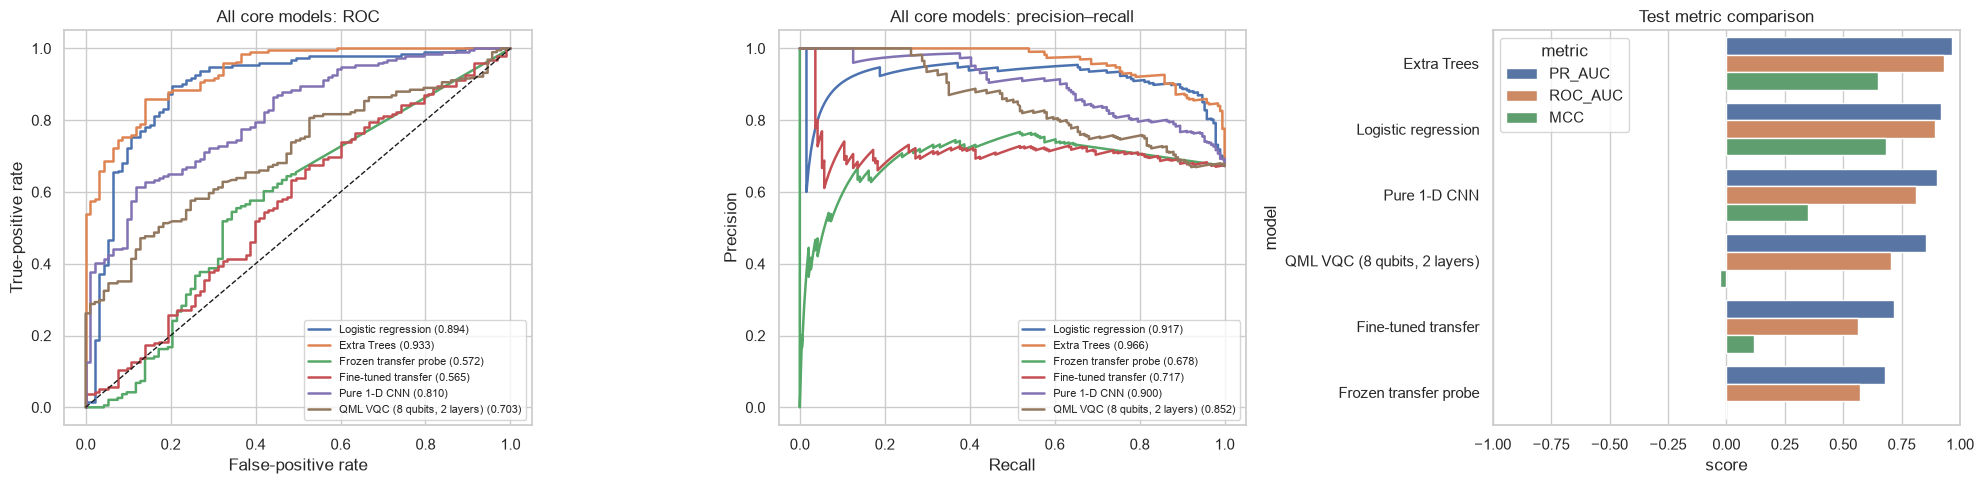

Best core model by test PR-AUC (for descriptive comparison only): Extra Trees
Validation-selected thresholds: {'Logistic regression': 0.43, 'Extra Trees': 0.44, 'Frozen transfer probe': 0.05, 'Fine-tuned transfer': 0.1, 'Pure 1-D CNN': 0.38, 'QML VQC (8 qubits, 2 layers)': 0.325}


In [20]:
results_df = pd.DataFrame(results).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(results_df.style.format(precision=3).background_gradient(subset=["PR_AUC", "ROC_AUC", "MCC"], cmap="YlGn"))
results_df.to_csv(OUTPUT_DIR / "test_metrics_all_core_models.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for name, score in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, score)
    precision, recall, _ = precision_recall_curve(y_test, score)
    axes[0].plot(fpr, tpr, lw=1.8, label=f"{name} ({roc_auc_score(y_test, score):.3f})")
    axes[1].plot(recall, precision, lw=1.8, label=f"{name} ({average_precision_score(y_test, score):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="All core models: ROC", xlabel="False-positive rate", ylabel="True-positive rate")
axes[1].set(title="All core models: precision–recall", xlabel="Recall", ylabel="Precision")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
plot_metrics = results_df.melt(id_vars="model", value_vars=["PR_AUC", "ROC_AUC", "MCC"], var_name="metric", value_name="score")
sns.barplot(data=plot_metrics, x="score", y="model", hue="metric", ax=axes[2])
axes[2].set(title="Test metric comparison", xlim=(-1, 1))
savefig("10_all_models_comparison.png")

best_core_model = results_df.iloc[0]["model"]
print(f"Best core model by test PR-AUC (for descriptive comparison only): {best_core_model}")
print("Validation-selected thresholds:", {k: round(v, 3) for k, v in thresholds.items()})

# Explainable AI

## A. Global explanations — SHAP for Extra Trees

SHAP values estimate each bit's contribution to a tree model's prediction. The plot identifies predictive **fingerprint bit positions**, not chemical atoms. Since Kaggle does not distribute the original bit-to-substructure mapping, these must be interpreted as feature-level signals and validated after reconstructing molecular fingerprints from SMILES.

## B. Local explanations — Integrated Gradients for the pure CNN

Integrated Gradients compares one molecule with an all-zero fingerprint baseline. Positive attribution means the active bit pushes the CNN toward the inhibitor class for that one prediction. It does not establish causal chemistry.

Computing TreeSHAP for 200 held-out molecules. This can take a few minutes.


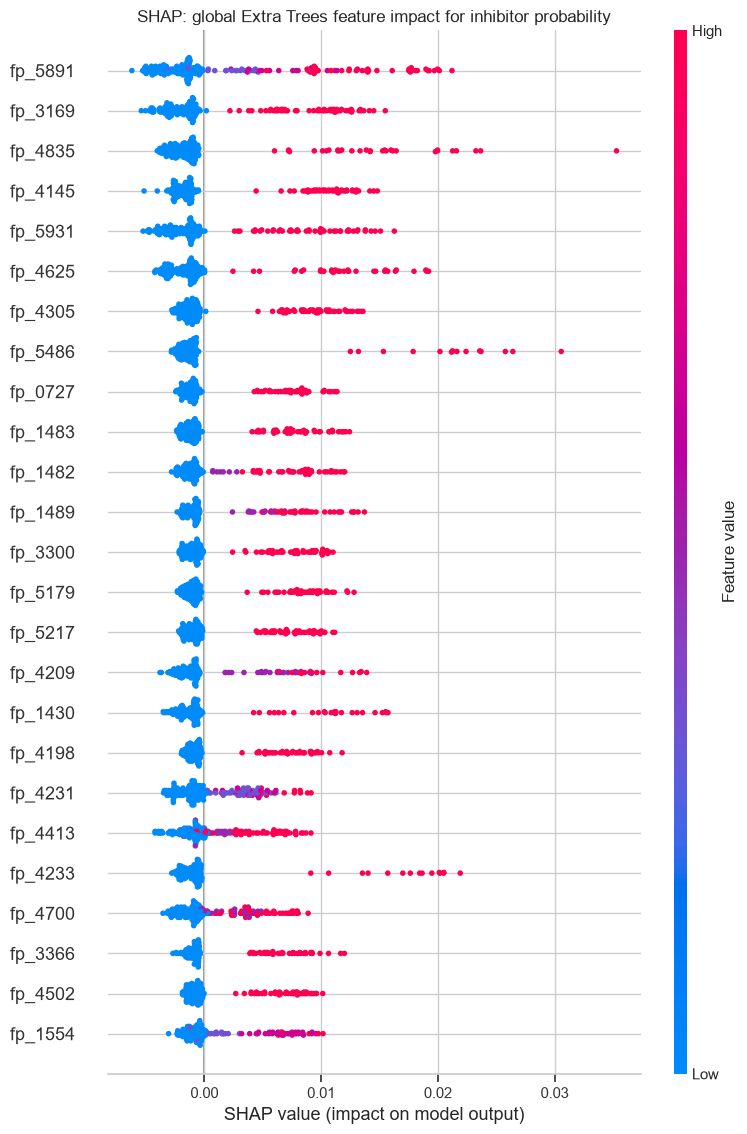

,feature,mean_abs_shap,feature_index,family
5891,fp_5891,0.005092,5891,tt
3169,fp_3169,0.004151,3169,mg
4835,fp_4835,0.003870,4835,tt
4145,fp_4145,0.003786,4145,tt
5931,fp_5931,0.003745,5931,tt
4625,fp_4625,0.003576,4625,tt
4305,fp_4305,0.003323,4305,tt
5486,fp_5486,0.002937,5486,tt
727,fp_0727,0.002847,727,ap
1483,fp_1483,0.002846,1483,ap


In [21]:
# A) SHAP global explanation for Extra Trees. Uses a bounded test sample to keep runtime practical.
try:
    import shap
except ImportError:
    subprocess.run(["python", "-m", "pip", "install", "-q", "shap"], check=True)
    import shap

TREE_XAI_MODEL = fitted_models["Extra Trees"]
N_SHAP_SAMPLES = min(200 if not FAST_RUN else 60, len(X_test))
rng = np.random.default_rng(SEED)
shap_idx = rng.choice(len(X_test), N_SHAP_SAMPLES, replace=False)
print(f"Computing TreeSHAP for {len(shap_idx)} held-out molecules. This can take a few minutes.")

explainer = shap.TreeExplainer(TREE_XAI_MODEL, feature_perturbation="tree_path_dependent")
raw_shap = explainer.shap_values(X_test[shap_idx], check_additivity=False)
# Compatibility across SHAP versions: list[n_classes], (n,f,n_classes), or (n,f).
if isinstance(raw_shap, list):
    shap_positive = raw_shap[1]
elif np.asarray(raw_shap).ndim == 3:
    shap_positive = np.asarray(raw_shap)[:, :, 1]
else:
    shap_positive = np.asarray(raw_shap)

shap.summary_plot(shap_positive, X_test[shap_idx], feature_names=feature_names, max_display=25, show=False)
plt.title("SHAP: global Extra Trees feature impact for inhibitor probability")
savefig("11_shap_global_extra_trees.png")

mean_abs_shap = np.abs(shap_positive).mean(axis=0)
shap_table = pd.DataFrame({"feature": feature_names, "mean_abs_shap": mean_abs_shap})
shap_table["feature_index"] = np.arange(len(feature_names))
shap_table["family"] = np.select(
    [(shap_table.feature_index >= sl.start) & (shap_table.feature_index < sl.stop) for sl in block_slices.values()],
    list(block_slices), default="other"
)
shap_table = shap_table.sort_values("mean_abs_shap", ascending=False)
display(shap_table.head(30))
shap_table.to_csv(OUTPUT_DIR / "shap_global_feature_importance.csv", index=False)

,feature,feature_index,fingerprint_value,integrated_gradient,absolute_attribution,family
1094,fp_1094,1094,51.0,3.306203,3.306203,ap
1104,fp_1104,1104,42.0,1.758151,1.758151,ap
1106,fp_1106,1106,54.0,1.446946,1.446946,ap
1096,fp_1096,1096,27.0,-1.326061,1.326061,ap
1099,fp_1099,1099,29.0,1.267667,1.267667,ap
1103,fp_1103,1103,31.0,-0.990284,0.990284,ap
1122,fp_1122,1122,23.0,0.816772,0.816772,ap
1126,fp_1126,1126,32.0,0.667097,0.667097,ap
1095,fp_1095,1095,36.0,0.593355,0.593355,ap
1093,fp_1093,1093,24.0,-0.457106,0.457106,ap


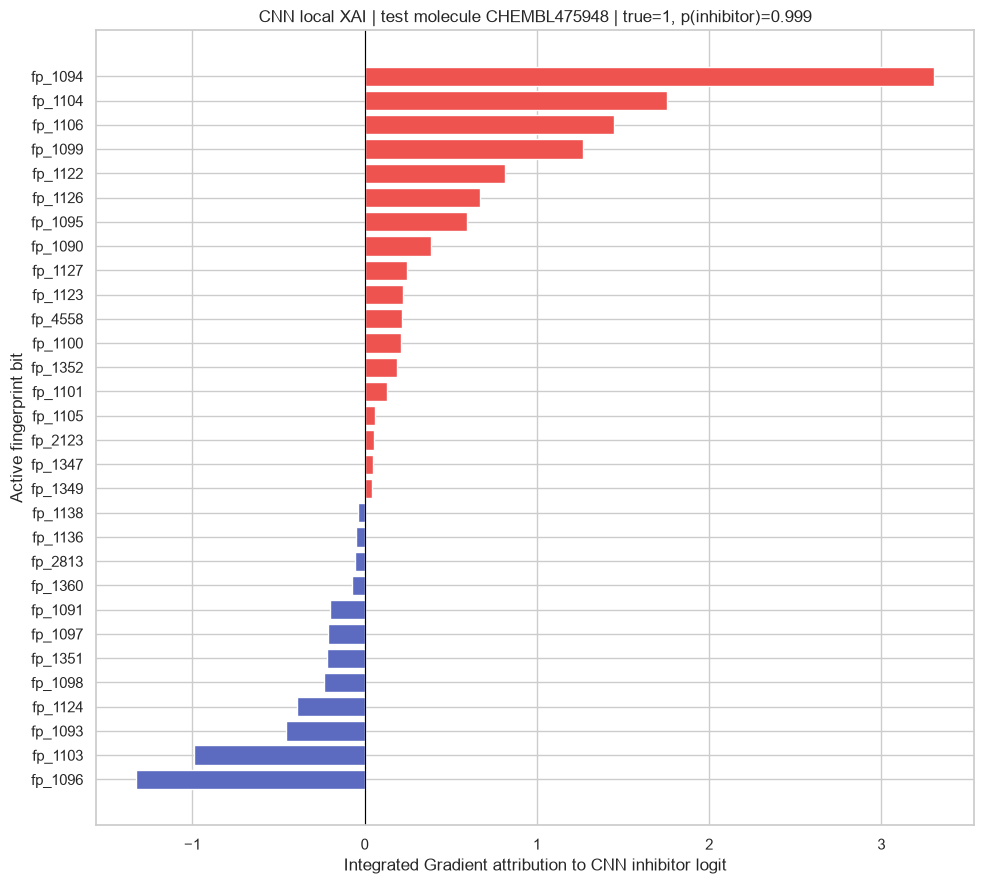

Interpretation note: `family` and bit index are the only defensible labels available from this Kaggle release.
To name fragments, retrieve SMILES and regenerate RDKit fingerprints while retaining bitInfo; do not reverse-map unsupported bit IDs.


In [22]:
# B) Integrated Gradients for one high-confidence CNN test prediction.
try:
    from captum.attr import IntegratedGradients
except ImportError:
    subprocess.run(["python", "-m", "pip", "install", "-q", "captum"], check=True)
    from captum.attr import IntegratedGradients

# Prefer a correctly predicted inhibitor; otherwise use the most confidently predicted test molecule.
cnn_pred = (cnn_test_prob >= thresholds[cnn_name]).astype(int)
valid_local = np.flatnonzero((y_test == 1) & (cnn_pred == 1))
local_position = int(valid_local[np.argmax(cnn_test_prob[valid_local])]) if len(valid_local) else int(np.argmax(cnn_test_prob))
local_global_idx = int(test_idx[local_position])

pure_cnn.eval()
input_tensor = torch.tensor(X_test[local_position:local_position+1], dtype=torch.float32, device=DEVICE)
ig = IntegratedGradients(pure_cnn)
attribution = ig.attribute(input_tensor, baselines=torch.zeros_like(input_tensor)).squeeze().detach().cpu().numpy()

local_table = pd.DataFrame({
    "feature": feature_names,
    "feature_index": np.arange(X.shape[1]),
    "fingerprint_value": X_test[local_position],
    "integrated_gradient": attribution,
    "absolute_attribution": np.abs(attribution),
})
local_table["family"] = np.select(
    [(local_table.feature_index >= sl.start) & (local_table.feature_index < sl.stop) for sl in block_slices.values()],
    list(block_slices), default="other"
)
# Active bits make the most intuitive molecule-level explanation.
local_active = local_table[local_table.fingerprint_value > 0].sort_values("absolute_attribution", ascending=False).head(30)
display(local_active)

plt.figure(figsize=(10, 9))
plot_local = local_active.sort_values("integrated_gradient")
colors = np.where(plot_local.integrated_gradient >= 0, "#EF5350", "#5C6BC0")
plt.barh(plot_local.feature, plot_local.integrated_gradient, color=colors)
plt.axvline(0, color="black", lw=.8)
plt.xlabel("Integrated Gradient attribution to CNN inhibitor logit")
plt.ylabel("Active fingerprint bit")
plt.title(
    f"CNN local XAI | test molecule {molecule_ids[local_global_idx]} | "
    f"true={y_test[local_position]}, p(inhibitor)={cnn_test_prob[local_position]:.3f}"
)
savefig("12_integrated_gradients_cnn_local.png")
local_active.to_csv(OUTPUT_DIR / "integrated_gradients_local_explanation.csv", index=False)

print("Interpretation note: `family` and bit index are the only defensible labels available from this Kaggle release.")
print("To name fragments, retrieve SMILES and regenerate RDKit fingerprints while retaining bitInfo; do not reverse-map unsupported bit IDs.")

## C. QML-specific explainability — permutation importance and quantum input gradients

The QML explanation has two complementary views:

- **Permutation importance:** shuffle one selected quantum input across held-out molecules and measure the drop in PR-AUC. This is model-agnostic and captures the effect of a bit after the train-only QML feature-selection step.
- **Input-gradient saliency:** differentiate the selected molecule's QML logit with respect to each encoded angle. The signed `gradient × input` value shows local sensitivity in the VQC's reduced feature space.

Both explanations map back to the selected **fingerprint bits**, not atoms or causal chemical fragments. Quantum gradients here are calculated on an ideal state-vector simulator; hardware gradients can differ in the presence of sampling and device noise.


,qml_wire,fingerprint_bit,baseline_PR_AUC,permuted_PR_AUC,PR_AUC_drop,baseline_ROC_AUC,permuted_ROC_AUC,ROC_AUC_drop
6,6,fp_5565,0.85243,0.768251,0.084179,0.703372,0.575410,0.127963
2,2,fp_1353,0.85243,0.794006,0.058424,0.703372,0.625063,0.078309
5,5,fp_4564,0.85243,0.797500,0.054930,0.703372,0.613128,0.090244
0,0,fp_0396,0.85243,0.801652,0.050778,0.703372,0.631706,0.071666
7,7,fp_5854,0.85243,0.806568,0.045862,0.703372,0.645274,0.058098
3,3,fp_1354,0.85243,0.819758,0.032672,0.703372,0.651269,0.052103
1,1,fp_0397,0.85243,0.822513,0.029917,0.703372,0.650453,0.052919
4,4,fp_4170,0.85243,0.836001,0.016429,0.703372,0.675393,0.027980


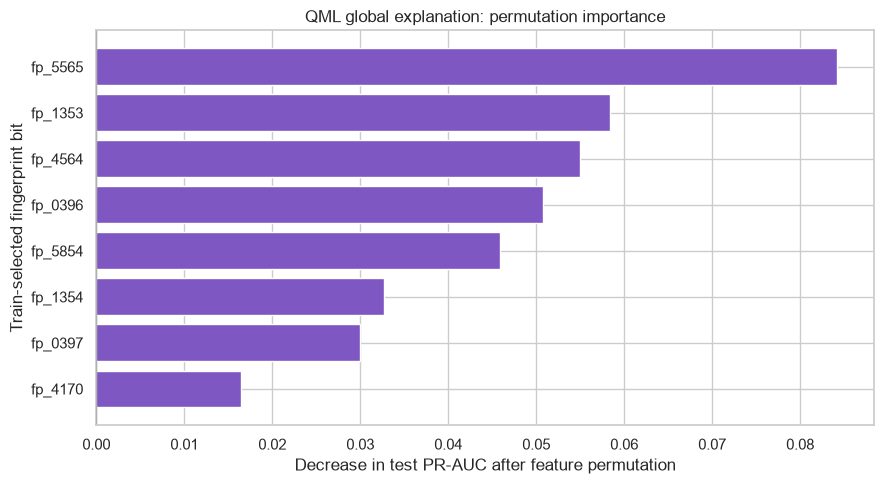

,qml_wire,fingerprint_bit,original_feature_index,encoded_angle,d_logit_d_angle,gradient_times_input,absolute_saliency
5,5,fp_4564,4564,-1.691627,-1.255070,2.123110,2.123110
3,3,fp_1354,1354,-2.072114,0.934478,-1.936345,1.936345
4,4,fp_4170,4170,-1.570796,1.029520,-1.617166,1.617166
7,7,fp_5854,5854,-1.912274,-0.602214,1.151599,1.151599
0,0,fp_0396,396,-1.795196,-0.483437,0.867865,0.867865
2,2,fp_1353,1353,-1.570796,-0.168923,0.265343,0.265343
1,1,fp_0397,397,-1.818817,-0.071827,0.130640,0.130640
6,6,fp_5565,5565,-2.210751,-0.001583,0.003500,0.003500


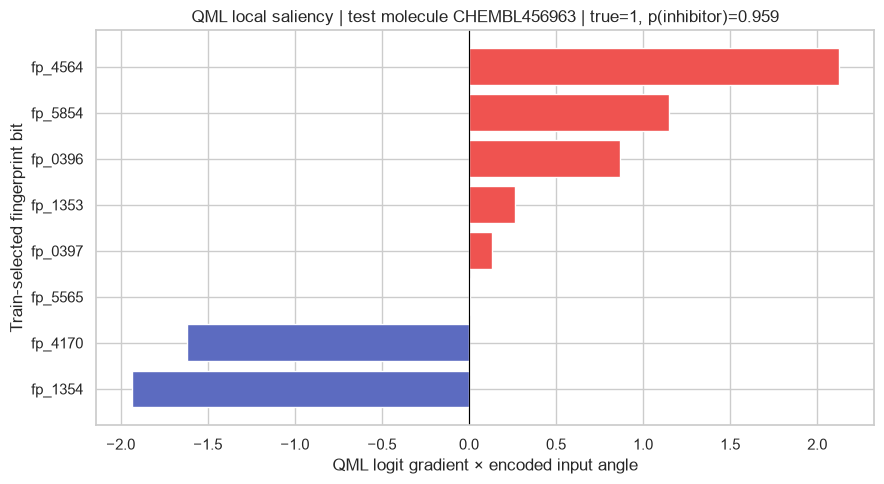

In [23]:
if RUN_QML:
    # 1) Global permutation importance on the untouched QML test inputs.
    baseline_qml_pr_auc = average_precision_score(y_test, qml_test_prob)
    baseline_qml_roc_auc = roc_auc_score(y_test, qml_test_prob)
    qml_rng = np.random.default_rng(SEED)
    permutation_rows = []

    for wire in range(QML_N_QUBITS):
        permuted = Xq_test.copy()
        permuted[:, wire] = qml_rng.permutation(permuted[:, wire])
        permuted_loader = qml_loader(permuted, y_test, batch_size=QML_BATCH_SIZE)
        permuted_prob, _ = predict_qml(qml_model, permuted_loader)
        permutation_rows.append({
            "qml_wire": wire,
            "fingerprint_bit": feature_names[qml_selected_original_idx[wire]],
            "baseline_PR_AUC": baseline_qml_pr_auc,
            "permuted_PR_AUC": average_precision_score(y_test, permuted_prob),
            "PR_AUC_drop": baseline_qml_pr_auc - average_precision_score(y_test, permuted_prob),
            "baseline_ROC_AUC": baseline_qml_roc_auc,
            "permuted_ROC_AUC": roc_auc_score(y_test, permuted_prob),
            "ROC_AUC_drop": baseline_qml_roc_auc - roc_auc_score(y_test, permuted_prob),
        })

    qml_permutation = pd.DataFrame(permutation_rows).sort_values("PR_AUC_drop", ascending=False)
    display(qml_permutation)
    qml_permutation.to_csv(OUTPUT_DIR / "qml_permutation_importance.csv", index=False)

    plt.figure(figsize=(9, 5))
    plot_perm = qml_permutation.sort_values("PR_AUC_drop")
    plt.barh(plot_perm["fingerprint_bit"], plot_perm["PR_AUC_drop"], color="#7E57C2")
    plt.axvline(0, color="black", lw=.8)
    plt.xlabel("Decrease in test PR-AUC after feature permutation")
    plt.ylabel("Train-selected fingerprint bit")
    plt.title("QML global explanation: permutation importance")
    savefig("13_qml_permutation_importance.png")

    # 2) Local QML saliency for a high-confidence predicted inhibitor.
    qml_pred = (qml_test_prob >= thresholds[qml_name]).astype(int)
    qml_candidates = np.flatnonzero((y_test == 1) & (qml_pred == 1))
    qml_local_position = (
        int(qml_candidates[np.argmax(qml_test_prob[qml_candidates])])
        if len(qml_candidates) else int(np.argmax(qml_test_prob))
    )
    qml_input = torch.tensor(
        Xq_test[qml_local_position:qml_local_position + 1],
        dtype=torch.float32, device=DEVICE, requires_grad=True
    )
    qml_model.eval()
    qml_model.zero_grad(set_to_none=True)
    qml_local_logit = qml_model(qml_input).squeeze()
    qml_local_probability = torch.sigmoid(qml_local_logit).item()
    qml_local_logit.backward()
    qml_gradient = qml_input.grad.detach().cpu().numpy().ravel()
    qml_angles = Xq_test[qml_local_position]

    qml_local_xai = pd.DataFrame({
        "qml_wire": np.arange(QML_N_QUBITS),
        "fingerprint_bit": feature_names[qml_selected_original_idx],
        "original_feature_index": qml_selected_original_idx,
        "encoded_angle": qml_angles,
        "d_logit_d_angle": qml_gradient,
        "gradient_times_input": qml_gradient * qml_angles,
        "absolute_saliency": np.abs(qml_gradient * qml_angles),
    }).sort_values("absolute_saliency", ascending=False)
    display(qml_local_xai)
    qml_local_xai.to_csv(OUTPUT_DIR / "qml_local_gradient_explanation.csv", index=False)

    plt.figure(figsize=(9, 5))
    plot_grad = qml_local_xai.sort_values("gradient_times_input")
    bar_colors = np.where(plot_grad["gradient_times_input"] >= 0, "#EF5350", "#5C6BC0")
    plt.barh(plot_grad["fingerprint_bit"], plot_grad["gradient_times_input"], color=bar_colors)
    plt.axvline(0, color="black", lw=.8)
    plt.xlabel("QML logit gradient × encoded input angle")
    plt.ylabel("Train-selected fingerprint bit")
    plt.title(
        f"QML local saliency | test molecule {molecule_ids[test_idx[qml_local_position]]} | "
        f"true={y_test[qml_local_position]}, p(inhibitor)={qml_local_probability:.3f}"
    )
    savefig("14_qml_local_gradient_saliency.png")
else:
    print("QML XAI skipped because RUN_QML=False.")


# Optional: rank molecules in the supplied PubChem file

If a `pubchem.h5` file is present, the next cell scores its vectors with an ensemble of the Extra Trees model and pure CNN. It exports a **model-prioritisation list**, not verified inhibitors. Before any wet-lab or downstream claim: remove known actives/data leakage, check applicability domain, inspect structures, validate assay conditions, and test experimentally.

In [24]:
if SCREEN_PUBCHEM:
    pubchem_path = find_dataset_file("pubchem")
    X_pub_sparse, y_pub_optional, pubchem_ids, _ = load_inhibitor_h5(pubchem_path, require_labels=False)
    if X_pub_sparse.shape[1] != X.shape[1]:
        raise ValueError(f"PubChem features have {X_pub_sparse.shape[1]} columns, expected {X.shape[1]}.")
    X_pub = X_pub_sparse.toarray().astype(np.float32, copy=False)
    tree_prob = fitted_models["Extra Trees"].predict_proba(X_pub)[:, 1]
    pub_loader = fp_loader(X_pub, np.zeros(len(X_pub), dtype=np.int64), batch_size=BATCH_SIZE)
    cnn_prob, _ = predict_torch(pure_cnn, pub_loader)
    ranking = pd.DataFrame({
        "pubchem_or_source_id": pubchem_ids,
        "extra_trees_probability": tree_prob,
        "cnn_probability": cnn_prob,
        "mean_ensemble_probability": (tree_prob + cnn_prob) / 2,
    }).sort_values("mean_ensemble_probability", ascending=False)
    display(ranking.head(30))
    ranking.to_csv(OUTPUT_DIR / f"{TARGET}_pubchem_model_ranking.csv", index=False)
    print("Saved ranking only. High scores are hypotheses requiring chemical and experimental validation.")
else:
    print("PubChem ranking skipped. Set SCREEN_PUBCHEM=True to run this optional research prioritisation step.")

PubChem ranking skipped. Set SCREEN_PUBCHEM=True to run this optional research prioritisation step.


# Reproducibility report and next steps

This cell stores a compact run manifest. Recommended extensions:

1. Run the notebook separately for all eight kinase targets and compare calibrated PR-AUC with confidence intervals.
2. Retrieve SMILES and use a scaffold split or time split to quantify chemical generalisation.
3. Audit duplicate/near-duplicate molecules across splits and across kinases.
4. Benchmark QML under equivalent feature budgets, shot budgets, and hardware-noise settings before making any quantum-performance claim.
5. Calibrate the selected model (e.g., isotonic/Platt calibration fitted on validation data) before probability-based ranking.
6. Validate apparent hits through orthogonal assays; do not infer human therapeutic efficacy from these models.

In [25]:
import platform
import sklearn

manifest = {
    "dataset": DATASET_SLUG,
    "target": TARGET,
    "h5_path": str(h5_path),
    "n_samples": int(len(y)),
    "n_features": int(X.shape[1]),
    "class_counts": {str(k): int(v) for k, v in pd.Series(y).value_counts().sort_index().items()},
    "split_sizes": {"train": int(len(train_idx)), "validation": int(len(val_idx)), "test": int(len(test_idx))},
    "seed": SEED,
    "qml": {"enabled": RUN_QML, "n_qubits": QML_N_QUBITS, "n_layers": QML_N_LAYERS, "train_cap_per_class": QML_TRAIN_PER_CLASS} if RUN_QML else {"enabled": False},
    "thresholds_from_validation": {k: float(v) for k, v in thresholds.items()},
    "package_versions": {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__, "torch": torch.__version__},
}
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))
print(f"\nSaved models, figures, explanations, metrics, split indices, and manifest under: {OUTPUT_DIR.resolve()}")

{
  "dataset": "xiaotawkaggle/inhibitors",
  "target": "cdk2",
  "h5_path": "C:\\Users\\MANO\\Downloads\\book chapter\\data\\inhibitors\\cdk2.h5",
  "n_samples": 1890,
  "n_features": 6117,
  "class_counts": {
    "0": 619,
    "1": 1271
  },
  "split_sizes": {
    "train": 1323,
    "validation": 283,
    "test": 284
  },
  "seed": 42,
  "qml": {
    "enabled": true,
    "n_qubits": 8,
    "n_layers": 2,
    "train_cap_per_class": 500
  },
  "thresholds_from_validation": {
    "Logistic regression": 0.43000000000000005,
    "Extra Trees": 0.44000000000000006,
    "Frozen transfer probe": 0.05,
    "Fine-tuned transfer": 0.1,
    "Pure 1-D CNN": 0.38,
    "QML VQC (8 qubits, 2 layers)": 0.325
  },
  "package_versions": {
    "python": "3.14.6",
    "numpy": "2.4.6",
    "pandas": "2.3.3",
    "sklearn": "1.9.0",
    "torch": "2.14.1+cpu"
  }
}

Saved models, figures, explanations, metrics, split indices, and manifest under: C:\Users\MANO\Downloads\book chapter\artifacts\cdk2
